# Analisis Hasil Eksperimen

**Bangun `networkDefinition.json` (infrastruktur)**

* Menjelaskan **topologi jaringan**:

  * Device apa saja (fog node, cloud, gateway, sensor).
  * Spesifikasi tiap device (IPT, RAM, dsb.).
  * Link antar device (bandwidth & delay).
* ➝ ini adalah **peta infrastruktur** yang jadi “panggung” untuk aplikasi dan user.

**Desain `appDefinition.json` (arsitektur aplikasi)**

* Menjelaskan **aplikasi yang berjalan di atas jaringan**:

  * Modul apa saja (service komputasi).
  * Kebutuhan resource tiap modul (MIPS, RAM).
  * Alur pesan antar modul (graph aplikasi).
* ➝ ini adalah **rancangan software** yang akan ditempatkan ke perangkat pada topologi.

**Deklarasi `usersDefinition.json` (workload user)**

* Menjelaskan **bagaimana pengguna memicu aplikasi**:

  * User X terhubung ke device Y (gateway).
  * User itu menjalankan App Z.
  * Request rate (`lambda`) menunjukkan seberapa sering user mengirim request.
* ➝ ini adalah **traffic generator** yang men-drive aplikasi di dalam topologi.

# A. Pembentukan Topologi -> Aplikasi -> User

In [ ]:
# --- Definisikan data_path ---
data_path = "/Users/adhitya/Project/exp/"   # ganti sesuai path kamu

import json
import pandas as pd
import os
import networkx as nx
import datetime as dt
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import math

## 1. Network Definition

In [2]:
"""
Struktur dari networkDefinition.json:
{"entity": [
    list of device, each with:
    {
        id: int,      # id dari device/node
        RAM: int,     # RAM dari device (MB)
        IPT: int,     # IPT (Instruction Per Time) dari device (instr/ms)
        TB: float,    # storage dari device (TB)
        TYPE: string, # tipe dari device: CLOUD, FG, CFG, FOG
    }
]},
{"link": [
    list of edge/link, each with:
    {
        s: int,       # source node id
        d: int,       # destination node id
        PR: int,      # propagation time (ms) atau delay saat propagasi
        BW: int,      # bandwidth dari link (bytes/ms)
    }
]}
"""

'\nStruktur dari networkDefinition.json:\n{"entity": [\n    list of device, each with:\n    {\n        id: int,      # id dari device/node\n        RAM: int,     # RAM dari device (MB)\n        IPT: int,     # IPT (Instruction Per Time) dari device (instr/ms)\n        TB: float,    # storage dari device (TB)\n        TYPE: string, # tipe dari device: CLOUD, FG, CFG, FOG\n    }\n]},\n{"link": [\n    list of edge/link, each with:\n    {\n        s: int,       # source node id\n        d: int,       # destination node id\n        PR: int,      # propagation time (ms) atau delay saat propagasi\n        BW: int,      # bandwidth dari link (bytes/ms)\n    }\n]}\n'

### 1.1 Topologi

In [3]:
with open(data_path + 'data/networkDefinition.json', 'r') as file:
    network_definition = json.load(file)

G = nx.Graph()

# Tambahkan node dengan semua atribut
for node in network_definition['entity']:
    node_id = node['id']
    node_attrs = {k: v for k, v in node.items() if k != 'id'}
    G.add_node(node_id, **node_attrs)

print(f"Total nodes ditambahkan: {G.number_of_nodes()}")

# Tambahkan edge dengan semua atribut
for link in network_definition['link']:
    source = link['s']
    dest = link['d']
    edge_attrs = {k: v for k, v in link.items() if k not in ['s', 'd']}
    G.add_edge(source, dest, **edge_attrs)

print(f"Total edges ditambahkan: {G.number_of_edges()}")

# Tampilkan contoh node dengan atribut
if G.nodes():
    sample_node = list(G.nodes(data=True))[0]
    print(f"\nSampel node: {sample_node}")

# Tampilkan contoh edge dengan atribut
if G.edges():
    sample_edge = list(G.edges(data=True))[0]
    print(f"Sampel edge: {sample_edge}")

# Kategorisasi node berdasarkan type
node_types = {}
for node_id, attrs in G.nodes(data=True):
    node_type = attrs.get('type', 'FOG')  # default FOG jika tidak ada type
    if node_type not in node_types:
        node_types[node_type] = []
    node_types[node_type].append(node_id)

print("\nDistribusi node berdasarkan jenisnya:")
for node_type, nodes in node_types.items():
    print(f"{node_type}: {len(nodes)} nodes - {nodes}")   

Total nodes ditambahkan: 101
Total edges ditambahkan: 201

Sampel node: (0, {'RAM': 10, 'IPT': 770, 'TB': 4.276883106405917, 'type': 'CFG'})
Sampel edge: (0, 1, {'PR': 5, 'BW': 75000})

Distribusi node berdasarkan jenisnya:
CFG: 5 nodes - [0, 1, 2, 9, 17]
FOG: 70 nodes - [3, 4, 5, 6, 8, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 30, 33, 34, 35, 36, 38, 39, 40, 42, 43, 45, 46, 48, 50, 51, 52, 53, 55, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 75, 78, 81, 82, 83, 84, 87, 88, 91, 92, 95, 96, 97, 98]
FG: 25 nodes - [7, 25, 31, 32, 37, 41, 44, 47, 49, 54, 56, 57, 73, 74, 76, 77, 79, 80, 85, 86, 89, 90, 93, 94, 99]
CLOUD: 1 nodes - [100]


### 1.2 Spesifikasi

In [4]:
# Ambil entity list dari networkDefinition.json
entities = pd.DataFrame(network_definition["entity"])

# Tampilkan tabel spesifikasi lengkap
print("=== Detail Spesifikasi Semua Device ===")
print(entities[["id","type","IPT","RAM"]].sort_values("type"))

# Buat folder 'network' jika belum ada
os.makedirs("1. network/", exist_ok=True)

# Simpan tabel spesifikasi lengkap ke file CSV
output_path = "1. network/detail_spesifikasi_device.csv"
entities[["id","type","TB","RAM","IPT"]].sort_values("type").to_csv(output_path, index=False)

print(entities[["id","type","TB","RAM","IPT"]].sort_values("type"))
print(f"Tabel spesifikasi berhasil disimpan ke: {output_path}")

=== Detail Spesifikasi Semua Device ===
    id type  IPT  RAM
0    0  CFG  770   10
1    1  CFG  640   23
2    2  CFG  613   16
17  17  CFG  942   25
9    9  CFG  628   20
..  ..  ...  ...  ...
34  34  FOG  985   21
33  33  FOG  679   19
30  30  FOG  122   14
28  28  FOG  770   12
50  50  FOG  213   25

[101 rows x 4 columns]
    id type        TB  RAM  IPT
0    0  CFG  4.276883   10  770
1    1  CFG  1.840021   23  640
2    2  CFG  3.064909   16  613
17  17  CFG  5.760404   25  942
9    9  CFG  3.719540   20  628
..  ..  ...       ...  ...  ...
34  34  FOG  9.826462   21  985
33  33  FOG  1.834275   19  679
30  30  FOG  6.492573   14  122
28  28  FOG  2.536369   12  770
50  50  FOG  6.065555   25  213

[101 rows x 5 columns]
Tabel spesifikasi berhasil disimpan ke: 1. network/detail_spesifikasi_device.csv


### 1.3 Visualisasi

CLOUD: 1, CFG: 5, FOG: 70, FG: 25


/var/folders/wv/xmd6tbzd5ng0cxlyp0swk29m0000gn/T/ipykernel_2787/840181098.py:90: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


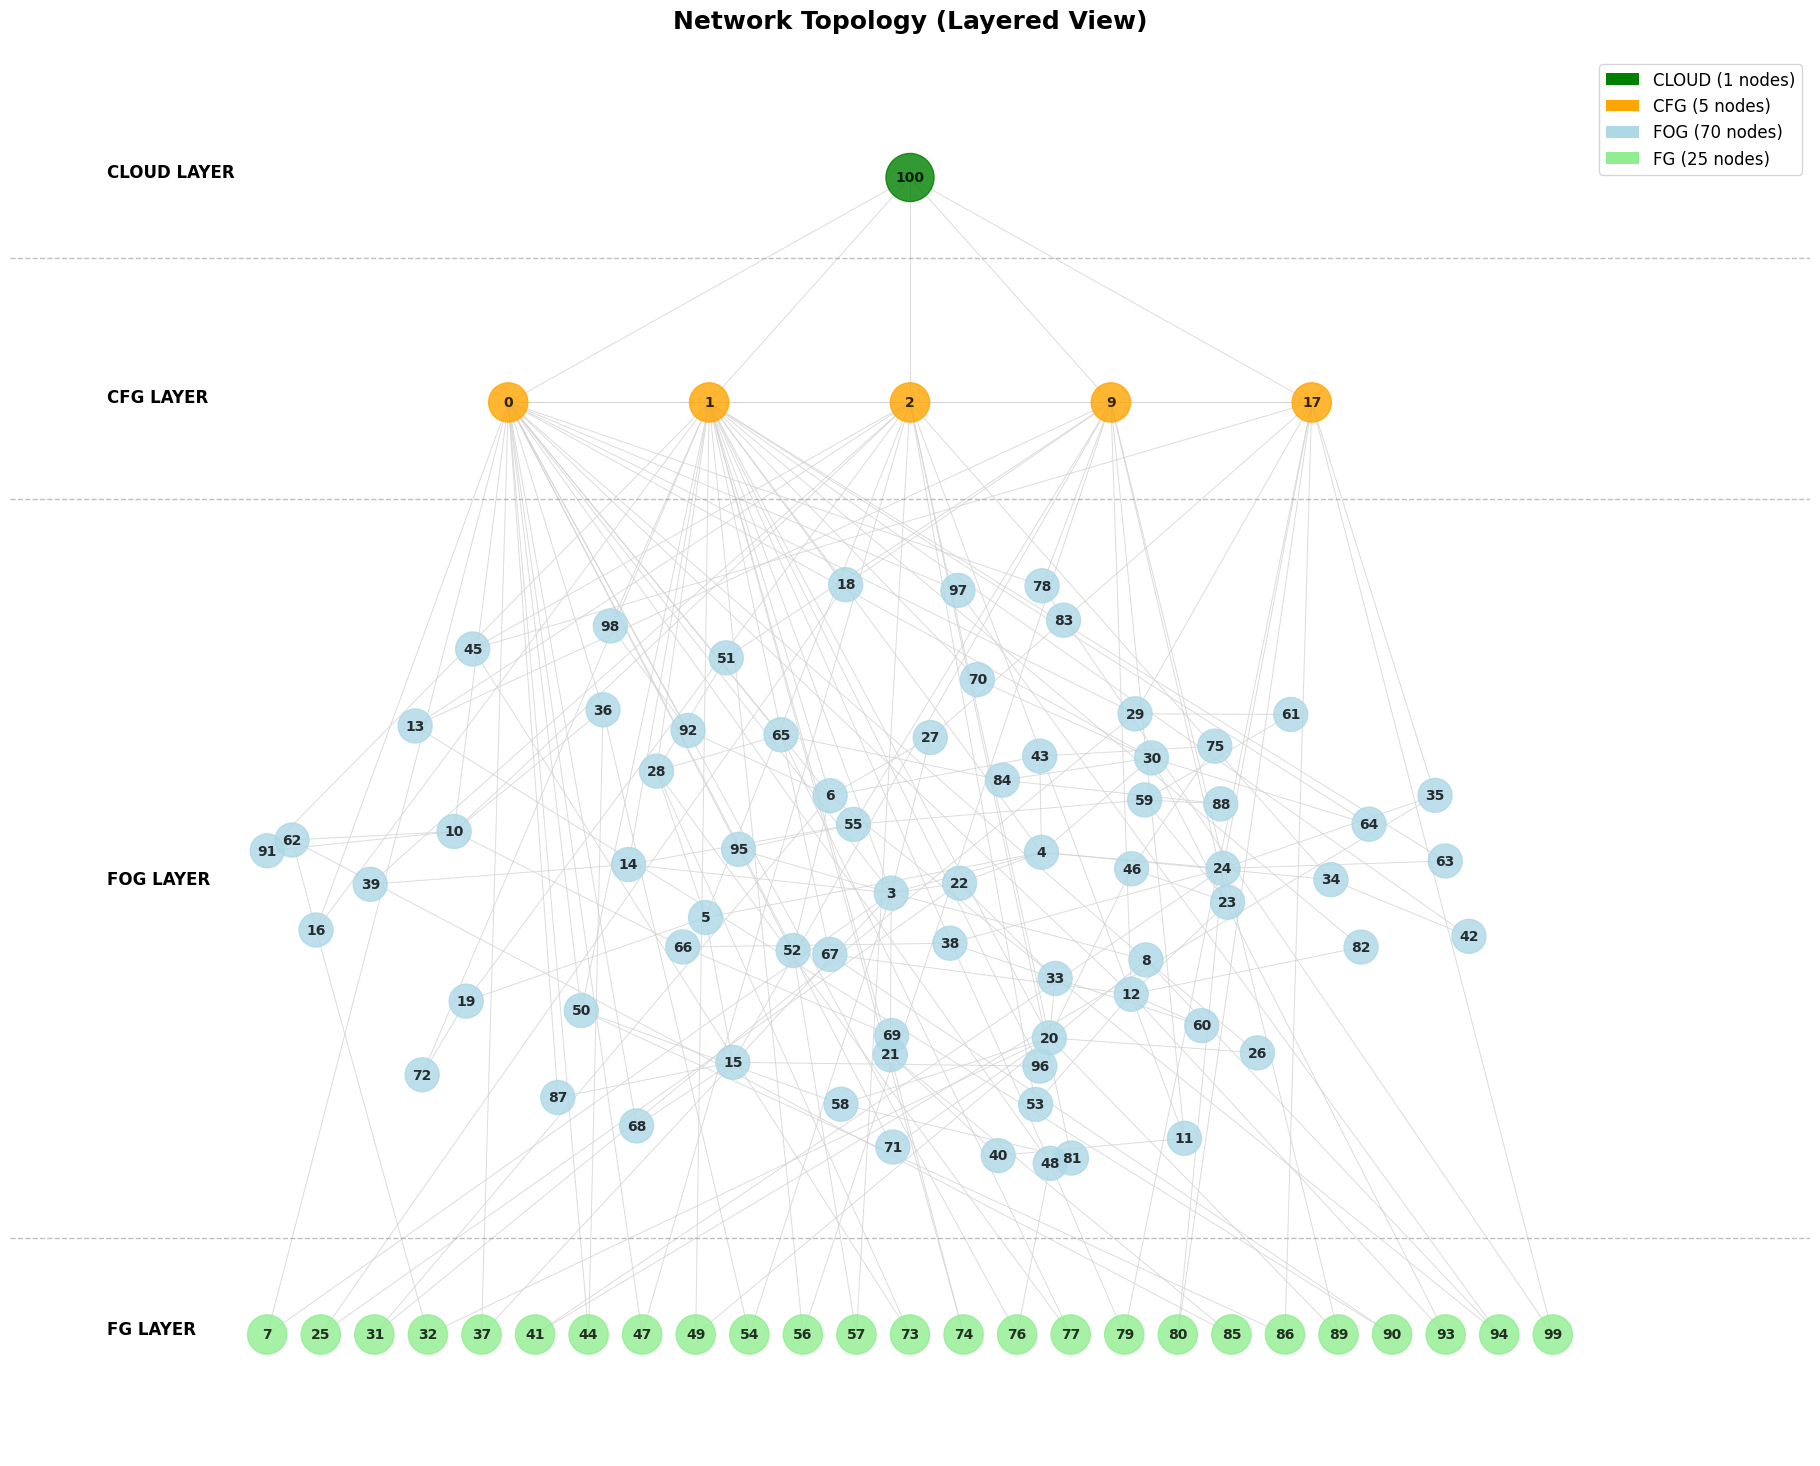

Gambar topologi tersimpan di: /Users/adhitya/Project/exp/1. network/topology_layers_20251003-223658.png

=== CLOUD CONNECTIONS ===
Cloud node 100 terhubung dengan 5 nodes: [0, 1, 2, 9, 17]

=== NODE DISTRIBUTION ===
CLOUD: 1 nodes
CFG:   5 nodes
FOG:   70 nodes
FG:    25 nodes
Total: 101 nodes


In [5]:
from matplotlib.patches import Patch

# --- folder & nama file output ---
save_dir = os.path.join(data_path, "1. network")
os.makedirs(save_dir, exist_ok=True)

ts = dt.datetime.now().strftime("%Y%m%d-%H%M%S")
out_path = os.path.join(save_dir, f"topology_layers_{ts}.png")

plt.figure(figsize=(18, 14))

# Warna per tipe node
color_map = {'CLOUD': 'green', 'CFG': 'orange', 'FOG': 'lightblue', 'FG': 'lightgreen'}

# Kategorisasi
cloud_nodes = [n for n in G.nodes() if G.nodes[n].get('type') == 'CLOUD']
cfg_nodes   = [n for n in G.nodes() if G.nodes[n].get('type') == 'CFG']
fog_nodes   = [n for n in G.nodes() if G.nodes[n].get('type') == 'FOG']
fg_nodes    = [n for n in G.nodes() if G.nodes[n].get('type') == 'FG']

print(f"CLOUD: {len(cloud_nodes)}, CFG: {len(cfg_nodes)}, FOG: {len(fog_nodes)}, FG: {len(fg_nodes)}")

# Layout manual berlapis
pos = {}

# Layer: CLOUD
y_cloud = 3.0
for i, node in enumerate(cloud_nodes):
    pos[node] = (0, y_cloud)

# Layer: CFG (spacing & centering)
y_cfg = 2.3
cfg_spacing = 2.5 / max(1, len(cfg_nodes) - 1) if len(cfg_nodes) > 1 else 0
for i, node in enumerate(cfg_nodes):
    x_cfg = -1.25 + i * cfg_spacing if len(cfg_nodes) > 1 else 0
    pos[node] = (x_cfg, y_cfg)

# Layer: FOG (spring layout dibatasi area)
if fog_nodes:
    fog_subgraph = G.subgraph(fog_nodes)
    fog_pos = nx.spring_layout(fog_subgraph, k=0.8, iterations=100, seed=42)
    y_fog, fog_width, fog_height = 0.8, 4.0, 2.0
    for node in fog_nodes:
        x_scaled = fog_pos[node][0] * fog_width/2
        y_scaled = fog_pos[node][1] * fog_height/2 + y_fog
        pos[node] = (x_scaled, y_scaled)

# Layer: FG
y_fg = -0.6
fg_spacing = 4.0 / max(1, len(fg_nodes) - 1) if len(fg_nodes) > 1 else 0
for i, node in enumerate(fg_nodes):
    x_fg = -2.0 + i * fg_spacing if len(fg_nodes) > 1 else 0
    pos[node] = (x_fg, y_fg)

# Warna & size
node_colors, node_sizes = [], []
for node in G.nodes():
    t = G.nodes[node].get('type', 'FOG')
    node_colors.append(color_map.get(t, 'gray'))
    size = 1200 if t == 'CLOUD' else 800 if t in ('CFG','FG') else 600
    node_sizes.append(size)

# Draw
nx.draw(
    G, pos,
    node_color=node_colors, node_size=node_sizes,
    with_labels=True, font_size=10, font_weight='bold', font_color='black',
    edge_color='lightgray', width=0.7, alpha=0.8
)

# Garis layer
plt.axhline(y=2.75, color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(y=2.0,  color='gray', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(y=-0.3, color='gray', linestyle='--', alpha=0.5, linewidth=1)

# Label layer
plt.text(-2.5, 3.0,  'CLOUD LAYER', fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, 2.3,  'CFG LAYER',   fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, 0.8,  'FOG LAYER',   fontsize=12, fontweight='bold', ha='left')
plt.text(-2.5, -0.6, 'FG LAYER',    fontsize=12, fontweight='bold', ha='left')

# Legend
legend_elements, legend_order = [], ['CLOUD','CFG','FOG','FG']
for t in legend_order:
    legend_elements.append(Patch(facecolor=color_map[t], label=f"{t} ({sum(G.nodes[n].get('type')==t for n in G.nodes())} nodes)"))
plt.legend(handles=legend_elements, loc='upper right', fontsize=12)

plt.title("Network Topology (Layered View)", fontsize=18, fontweight='bold', pad=20)
plt.axis('equal')
plt.tight_layout()

# --- SIMPAN SEBELUM SHOW ---
plt.savefig(out_path, dpi=200, bbox_inches='tight')  # <--- penting
plt.show()

print(f"Gambar topologi tersimpan di: {out_path}")

# Info tambahan
print("\n=== CLOUD CONNECTIONS ===")
if cloud_nodes:
    cloud_node = cloud_nodes[0]
    cloud_neighbors = list(G.neighbors(cloud_node))
    print(f"Cloud node {cloud_node} terhubung dengan {len(cloud_neighbors)} nodes: {cloud_neighbors}")

print("\n=== NODE DISTRIBUTION ===")
print(f"CLOUD: {len(cloud_nodes)} nodes")
print(f"CFG:   {len(cfg_nodes)} nodes")
print(f"FOG:   {len(fog_nodes)} nodes")
print(f"FG:    {len(fg_nodes)} nodes")
print(f"Total: {len(G.nodes())} nodes")

## 2. Application Definition

In [6]:
"""
Struktur dari appDefinition.json:
[
list of each application, each with:
    {
        id: int,
        name: string,
        deadline: int,  # deadline aplikasi (ms)
        module: [
            list of module, each with:
            {
                id: int,
                name: string,   # nama tiap module
                RAM: int,       # RAM yang dibutuhkan (MB)
                type: string,   # tipe dari module: MODULE, SOURCE, SINK
            }
        ],
        message: [
            list of message, each with:
            {
                id: int,
                name: string,
                s: string,         # nama module yang jadi sumber
                d: string,         # nama module yang jadi tujuan
                instructions: int  # jumlah instruksi yang diperlukan tiap request
                bytes: int,        # size dari message (bytes)
            }
        ],
        transmission: [
            list of transmission, each with:
            {
                module: string,         # nama module yang memproses
                message_in: string,     # nama message yang masuk
                message_out: string,    # nama message yang keluar
            }
        ]
    }
]
"""

'\nStruktur dari appDefinition.json:\n[\nlist of each application, each with:\n    {\n        id: int,\n        name: string,\n        deadline: int,  # deadline aplikasi (ms)\n        module: [\n            list of module, each with:\n            {\n                id: int,\n                name: string,   # nama tiap module\n                RAM: int,       # RAM yang dibutuhkan (MB)\n                type: string,   # tipe dari module: MODULE, SOURCE, SINK\n            }\n        ],\n        message: [\n            list of message, each with:\n            {\n                id: int,\n                name: string,\n                s: string,         # nama module yang jadi sumber\n                d: string,         # nama module yang jadi tujuan\n                instructions: int  # jumlah instruksi yang diperlukan tiap request\n                bytes: int,        # size dari message (bytes)\n            }\n        ],\n        transmission: [\n            list of transmission, each with

### 2.1 Messages dan Module

In [7]:
# --- LOAD ---
with open(data_path + 'data/appDefinition.json', 'r') as file:
    app_definition = json.load(file)

modules_data, messages_data, transmissions_data = [], [], []

for app in app_definition:
    app_id = app["id"]
    app_name = app.get("name", str(app_id))

    # modules
    for m in app.get("module", []):
        modules_data.append({
            "app_id": app_id,
            "app_name": app_name,
            "module_id": m["id"],
            "module_name": m.get("name", str(m["id"])),
            "RAM": m.get("RAM", 0),
            "MIPS": m.get("MIPS", 0)
        })

    # messages
    for msg in app.get("message", []):
        src = msg.get("src") or msg.get("s") or msg.get("source") or msg.get("from")
        dst = msg.get("dst") or msg.get("d") or msg.get("destination") or msg.get("to")
        messages_data.append({
            "app_id": app_id,
            "app_name": app_name,
            "msg_id": msg.get("id", None),
            "src": src,
            "dst": dst,
            "bytes": msg.get("bytes", 0),
            "instructions": msg.get("instructions", 0)
        })

    # transmissions
    for tr in app.get("transmission", []):
        transmissions_data.append({
            "app_id": app_id,
            "app_name": app_name,
            "module": tr.get("module"),
            "message_in": tr.get("message_in"),
            "message_out": tr.get("message_out", None)  # bisa kosong
        })

modules_df = pd.DataFrame(modules_data)
messages_df = pd.DataFrame(messages_data)
transmissions_df = pd.DataFrame(transmissions_data)

# --- SAVE ---
save_dir = os.path.join(data_path, "2. aplikasi")
os.makedirs(save_dir, exist_ok=True)

modules_df.to_csv(os.path.join(save_dir, "app_modules.csv"), index=False)
messages_df.to_csv(os.path.join(save_dir, "app_messages.csv"), index=False)
transmissions_df.to_csv(os.path.join(save_dir, "app_transmissions.csv"), index=False)

print(f"[OK] modules_df: {modules_df.shape}")
print(f"[OK] messages_df: {messages_df.shape}")
print(f"[OK] transmissions_df: {transmissions_df.shape}")
print("\nSemua file berhasil disimpan di folder:", save_dir)



[OK] modules_df: (138, 6)
[OK] messages_df: (138, 7)
[OK] transmissions_df: (202, 5)

Semua file berhasil disimpan di folder: /Users/adhitya/Project/exp/2. aplikasi


### 2.2 Visualisasi Messages

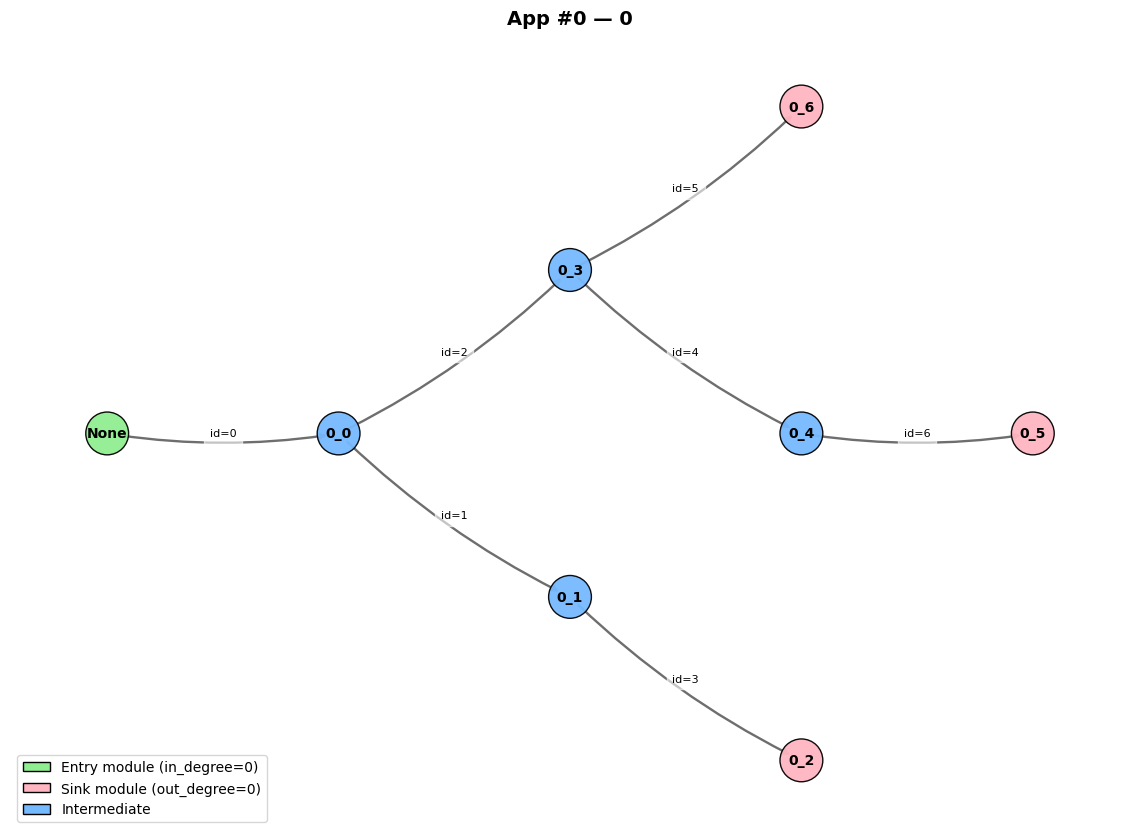

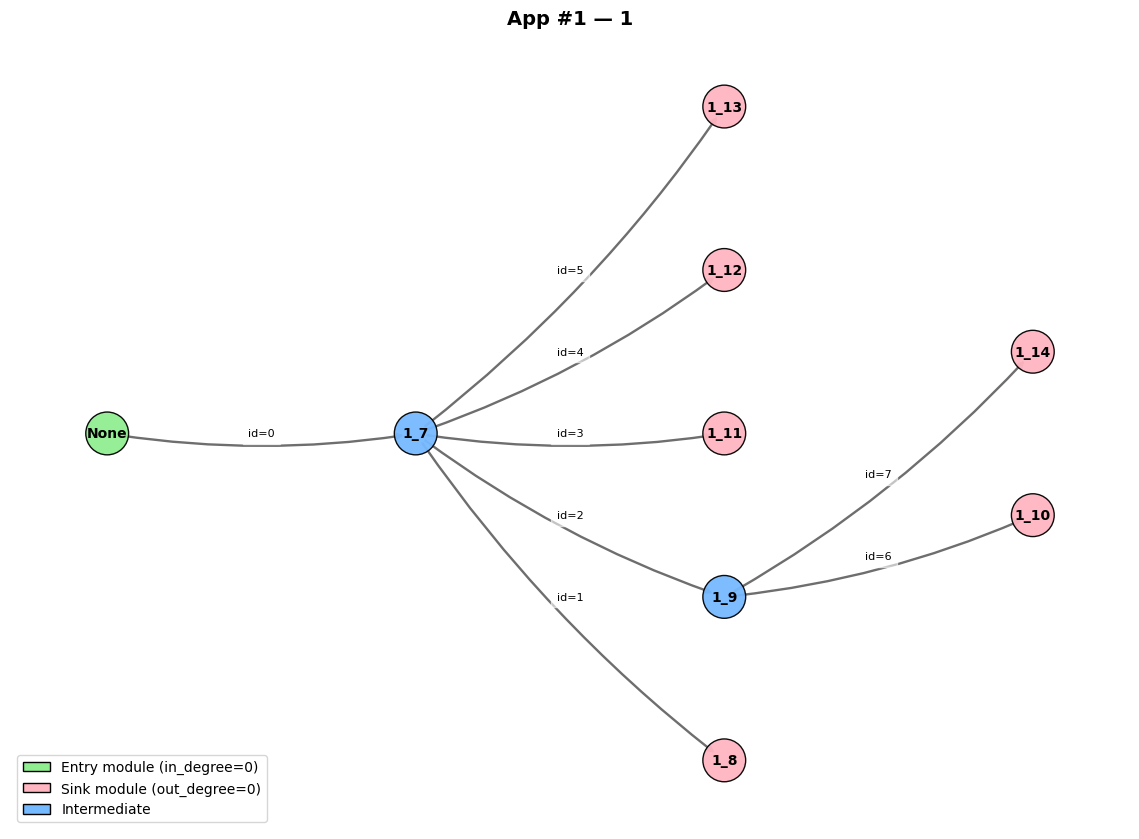

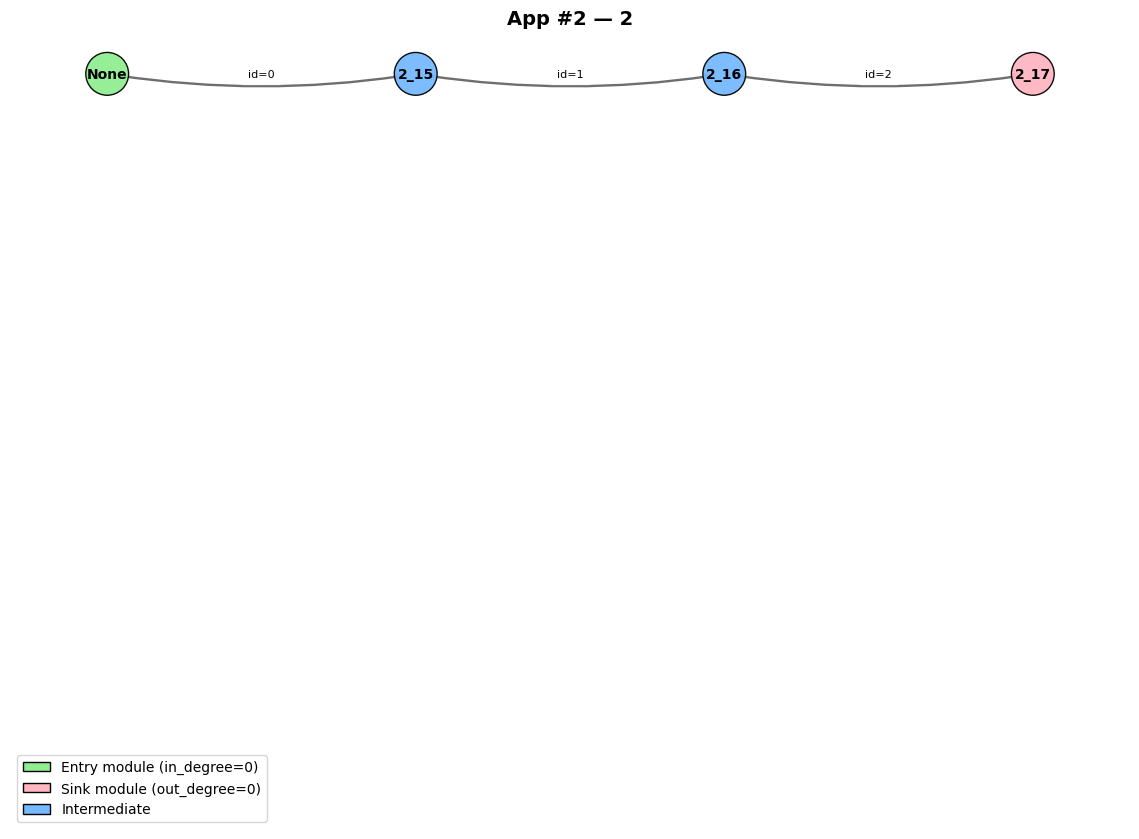

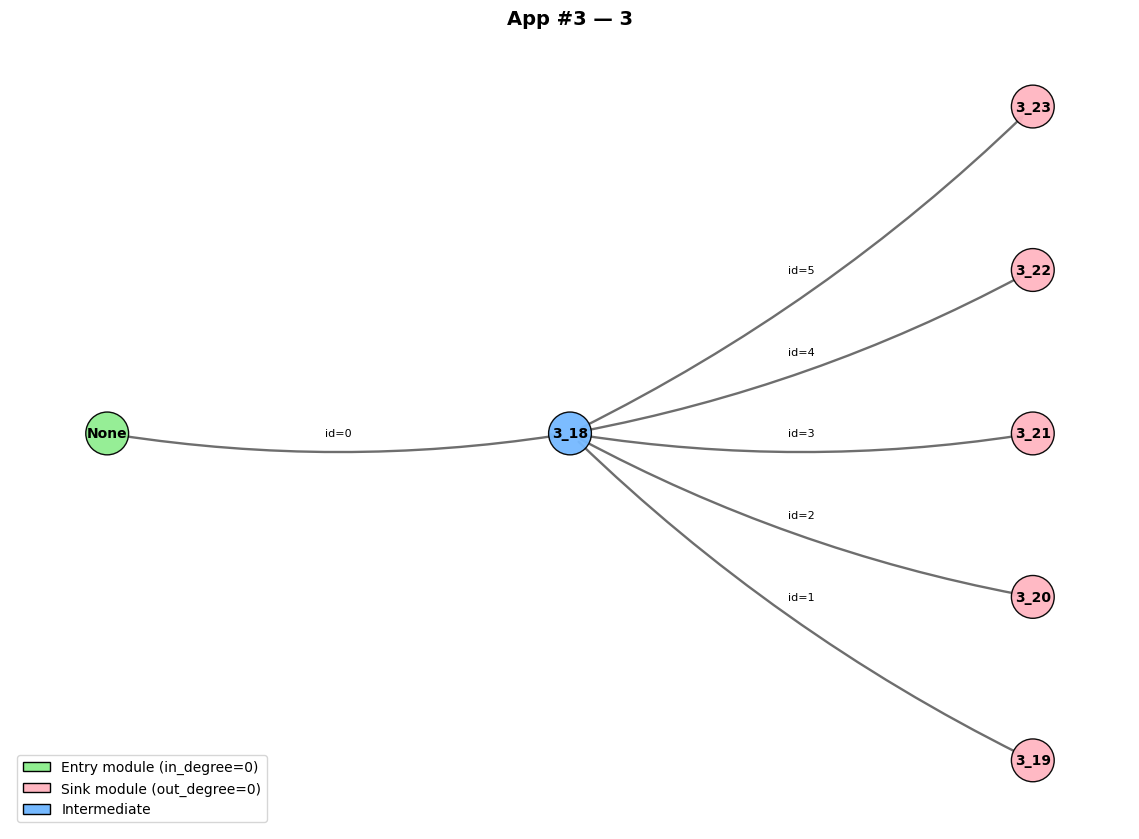

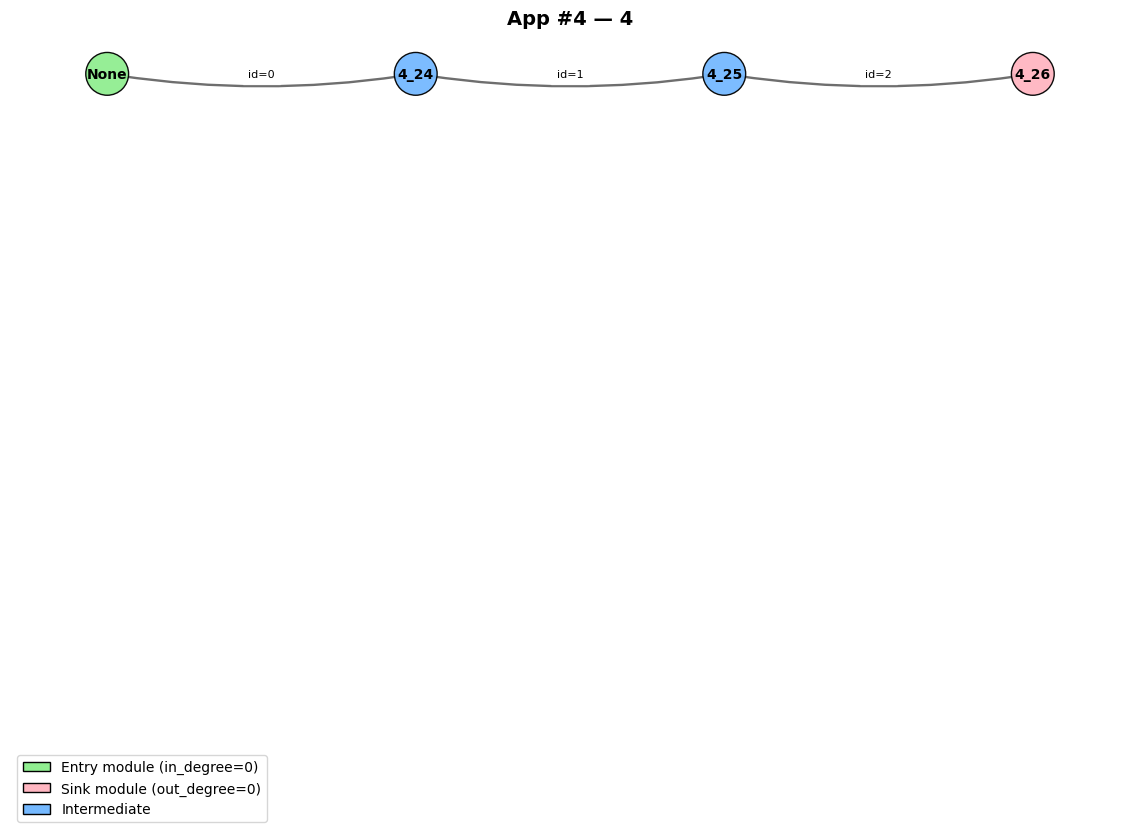

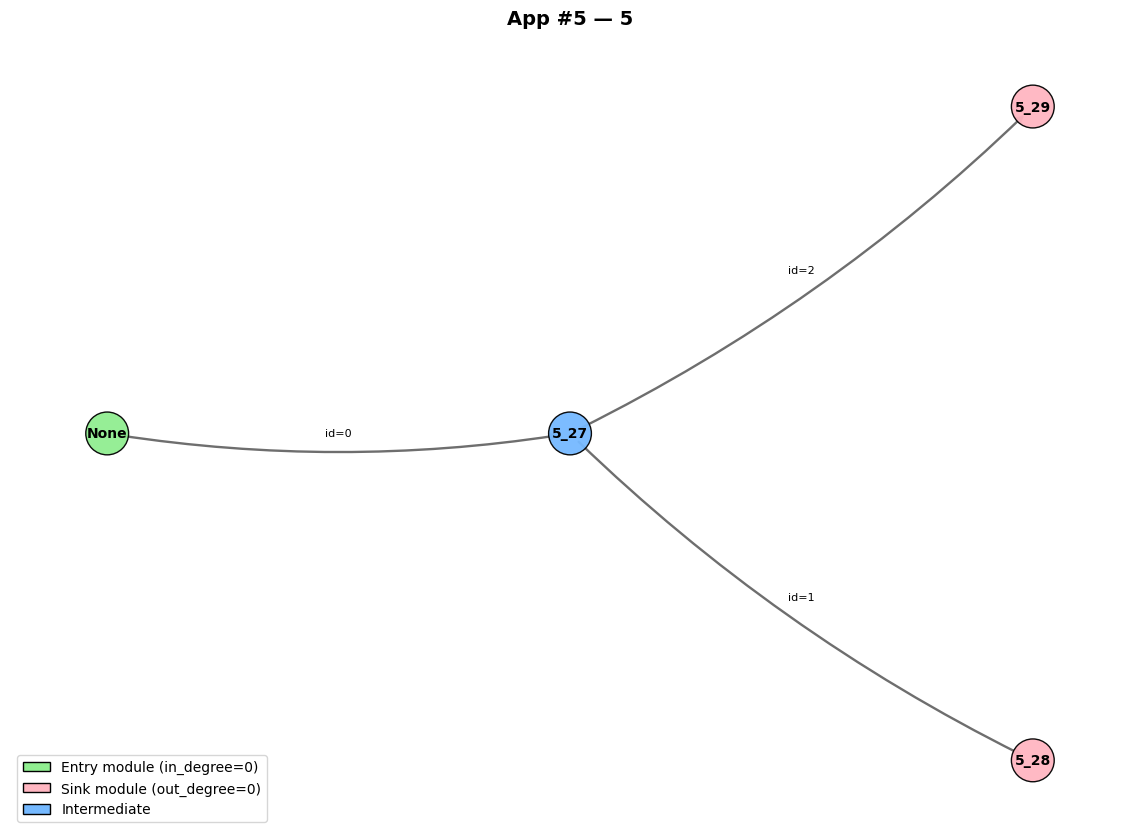

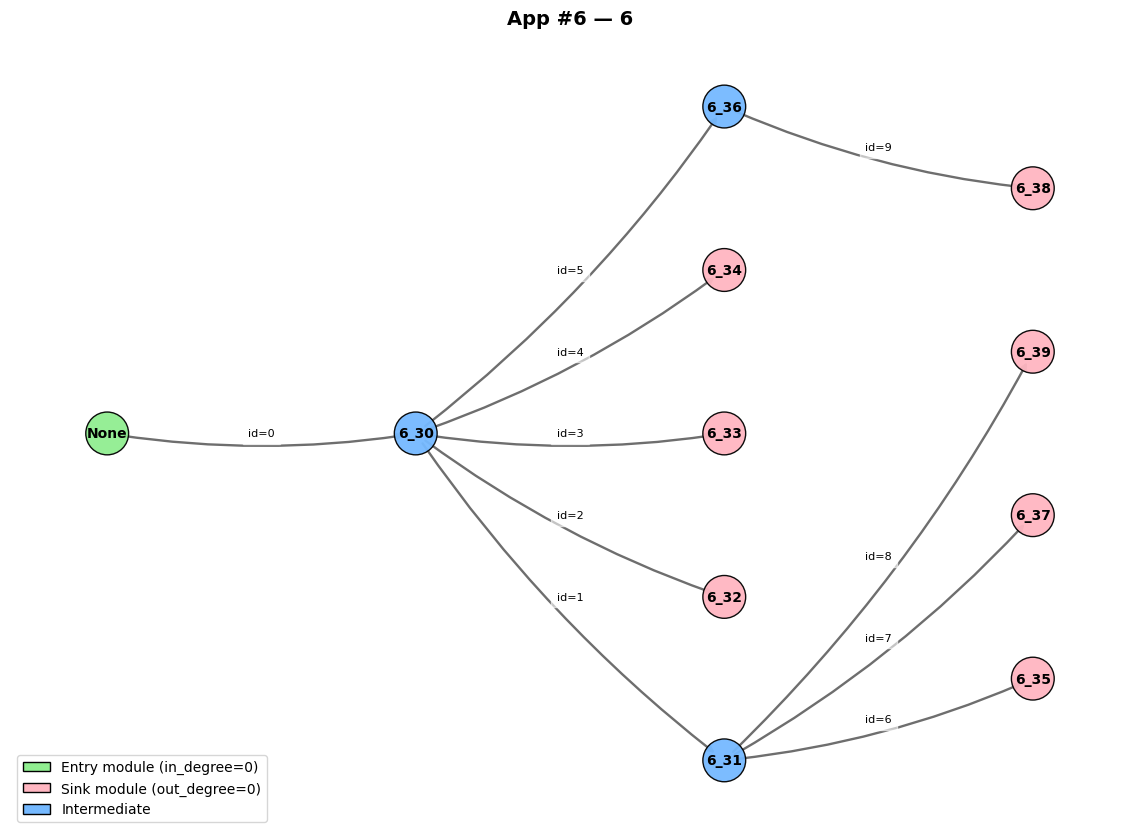

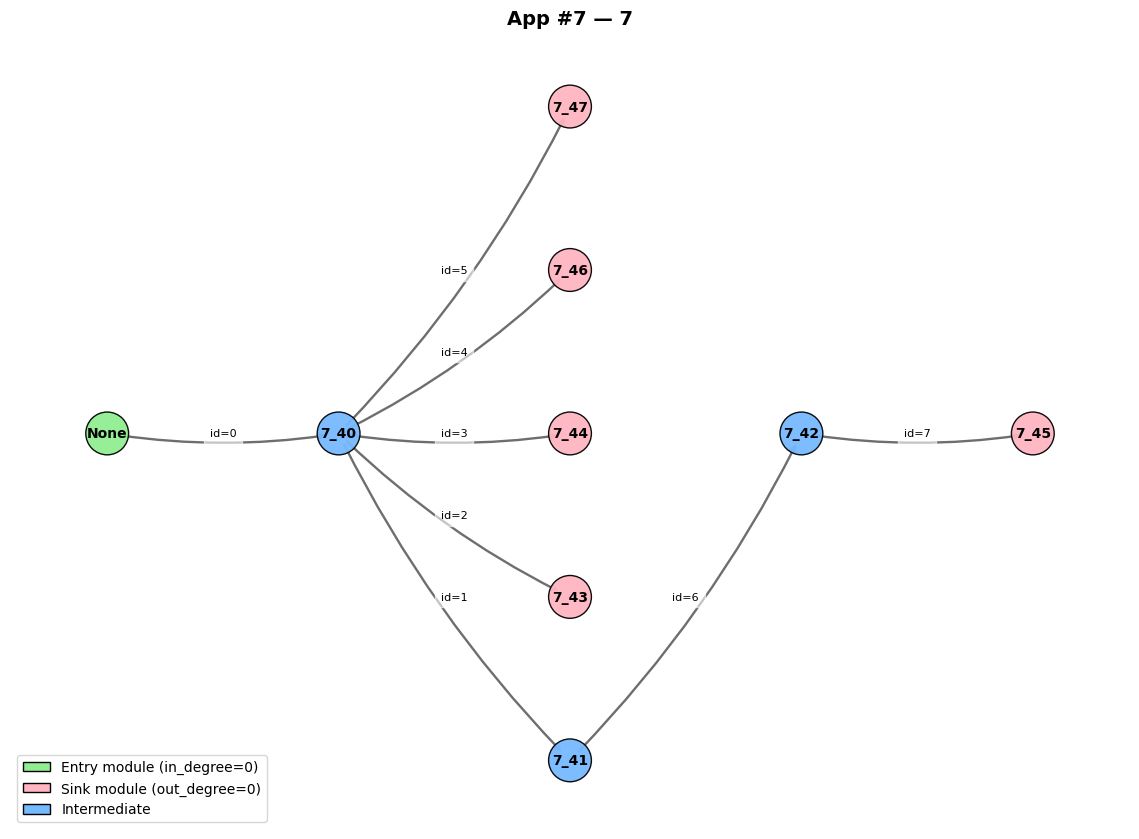

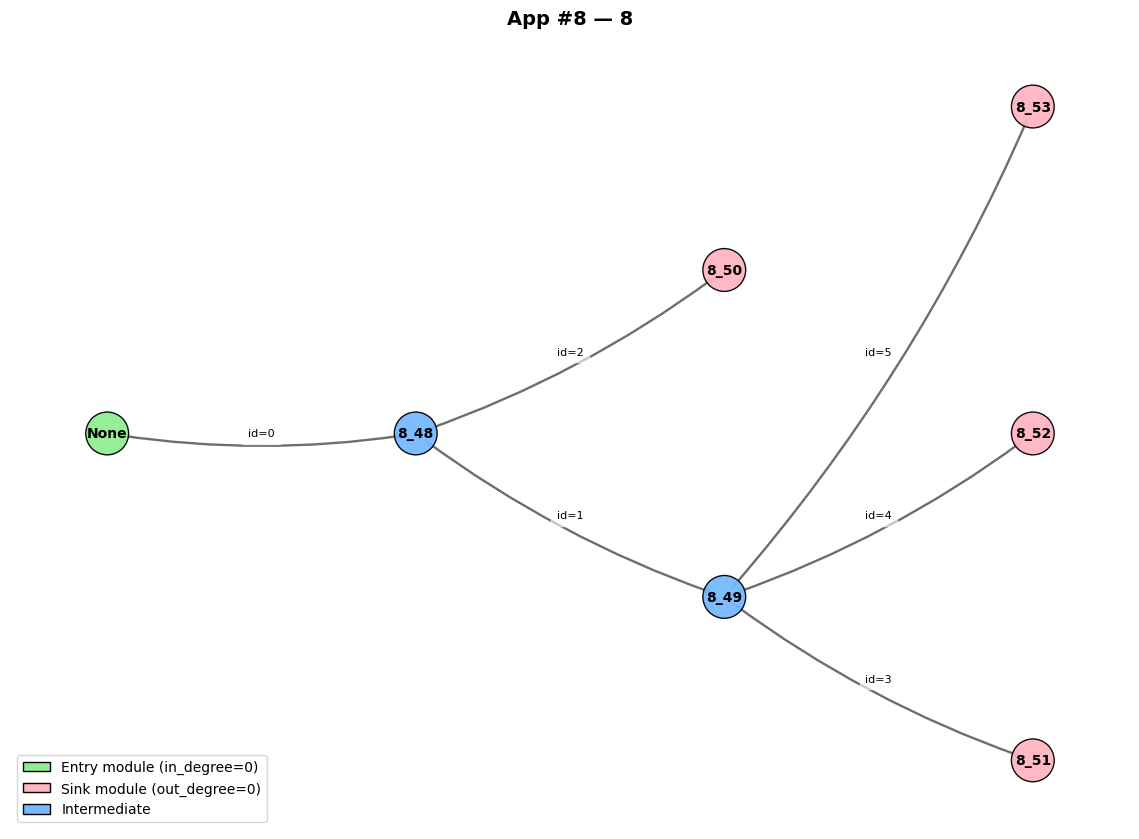

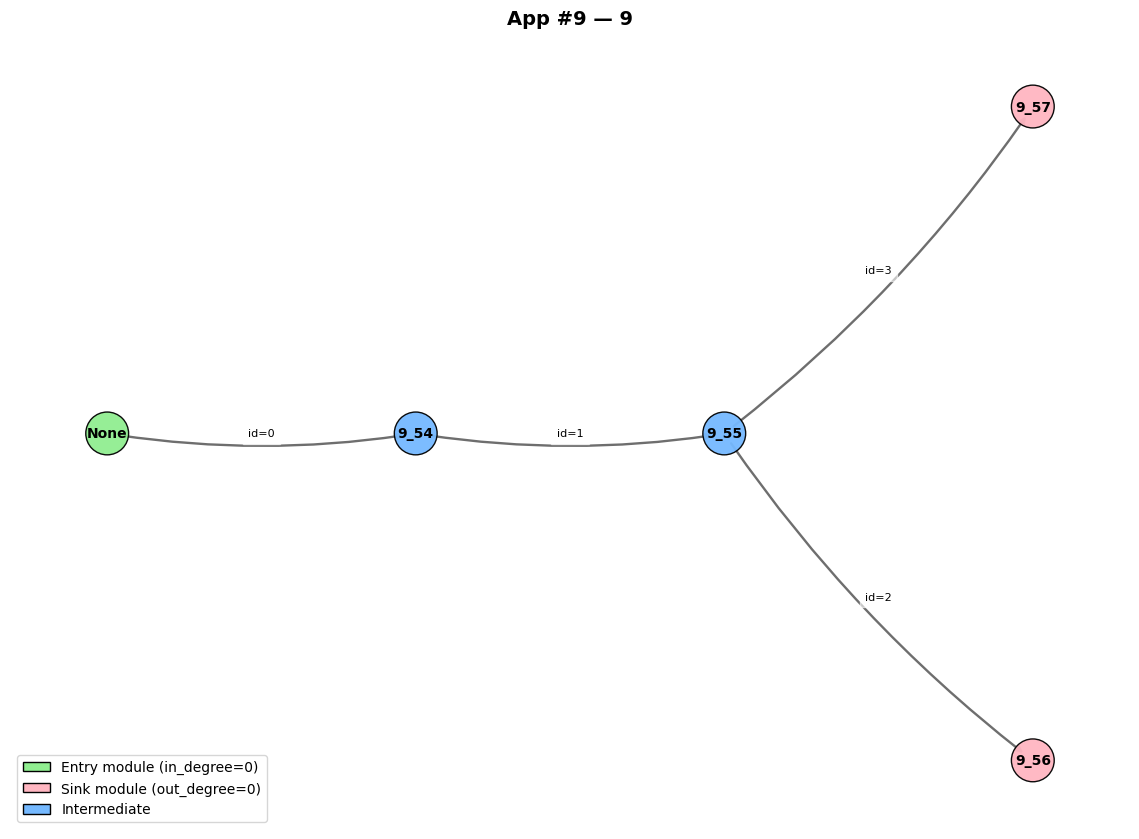

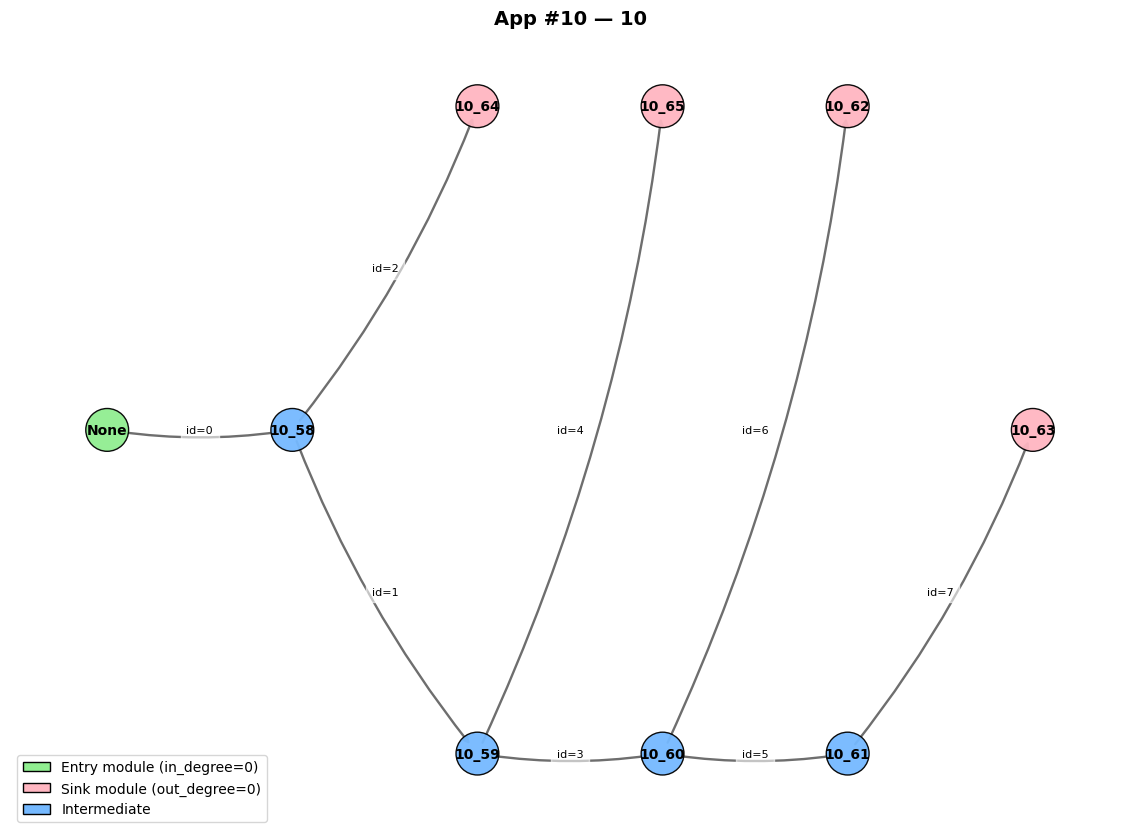

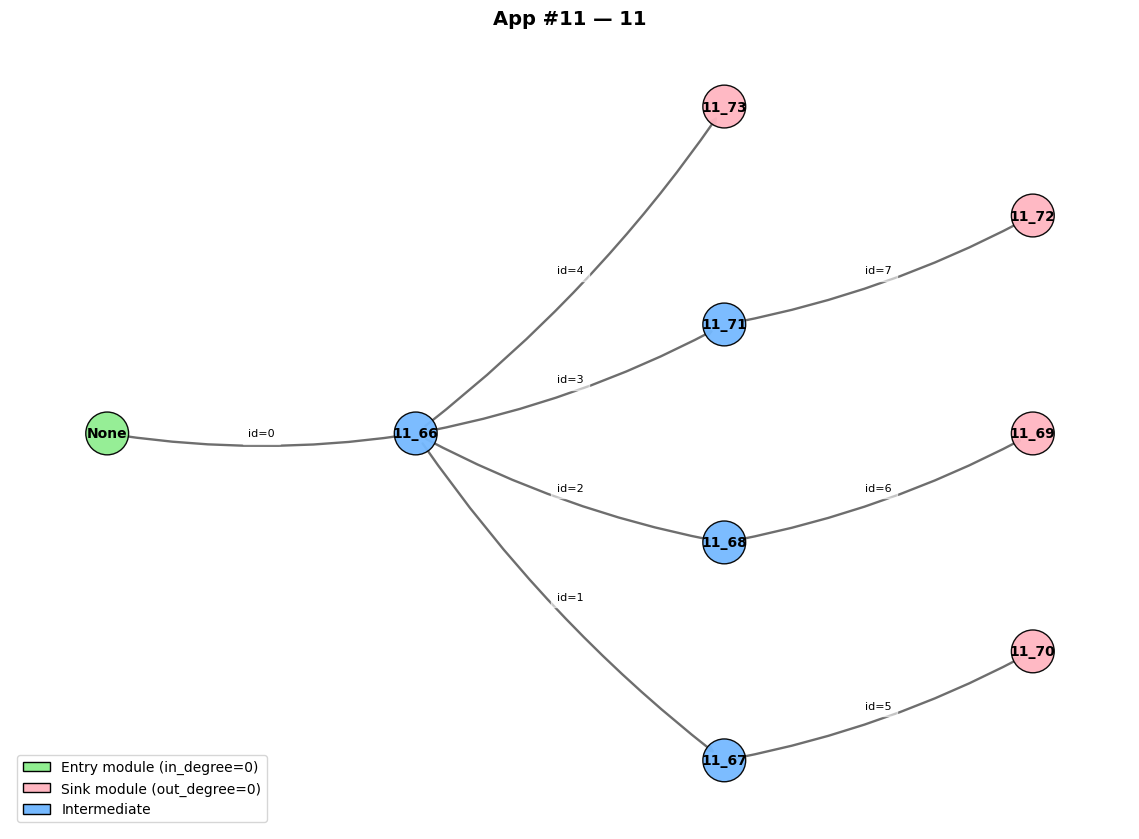

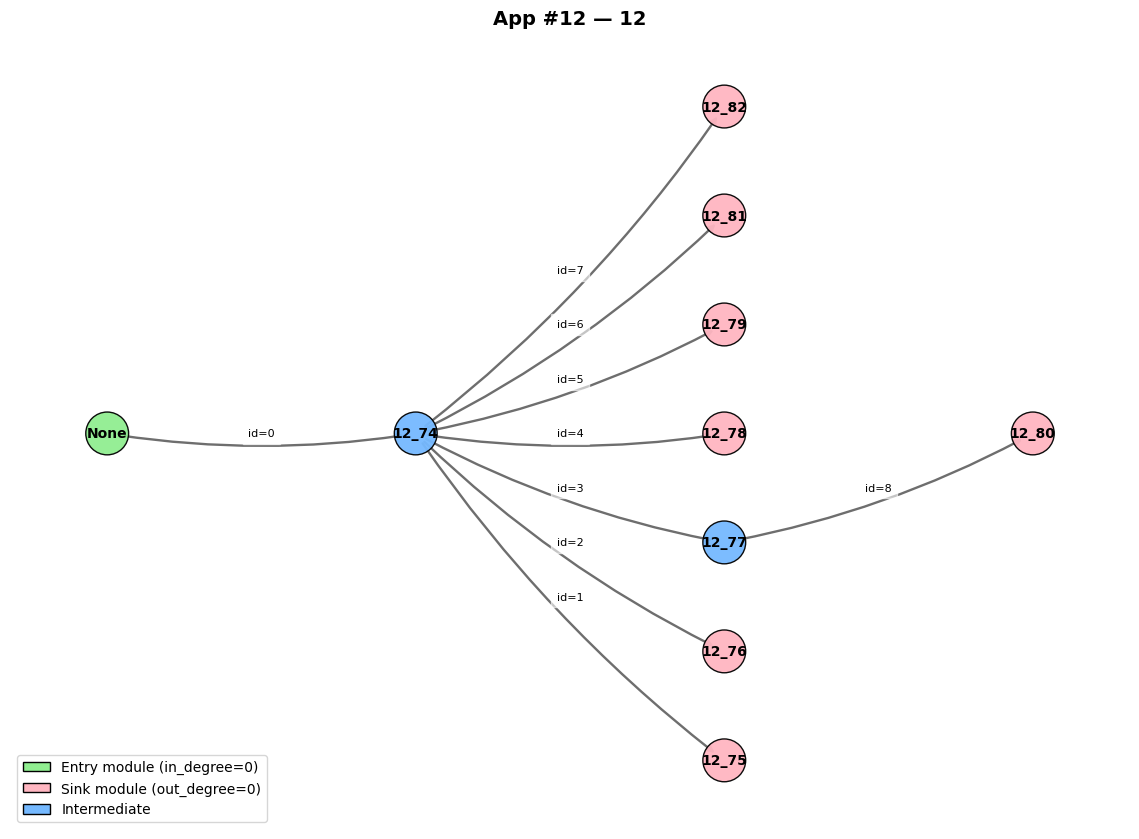

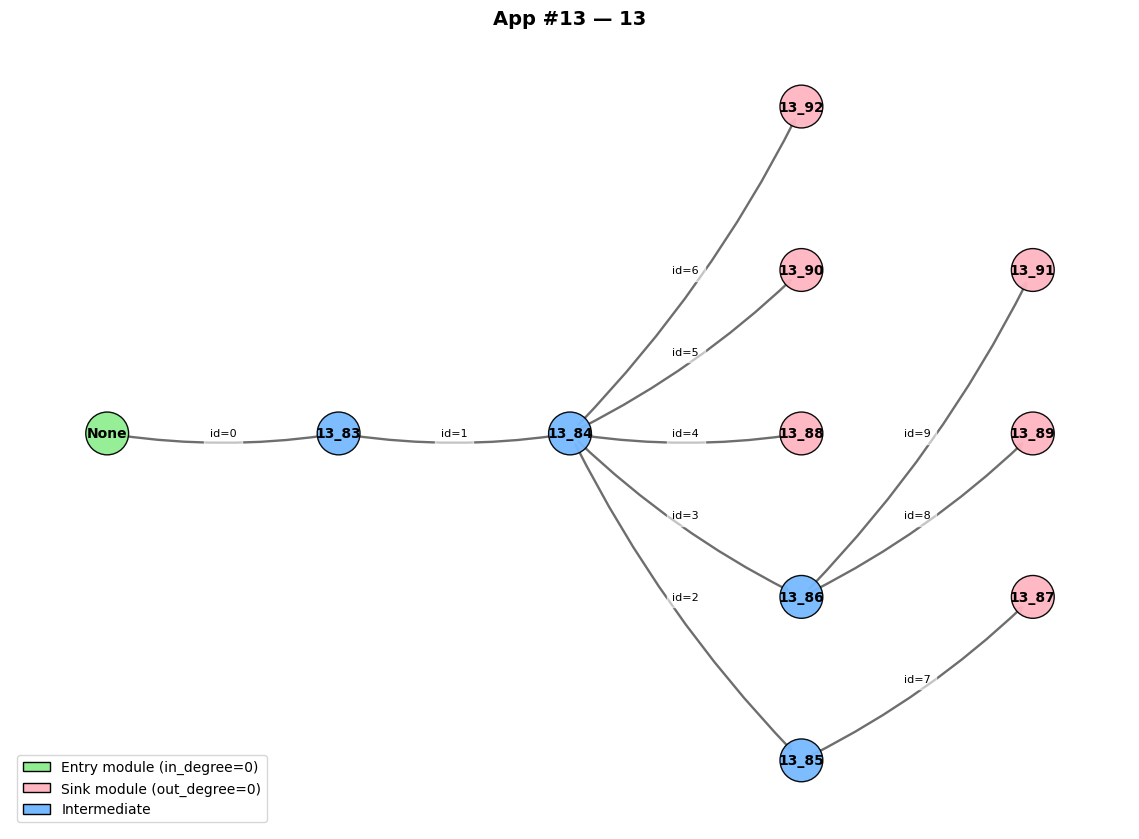

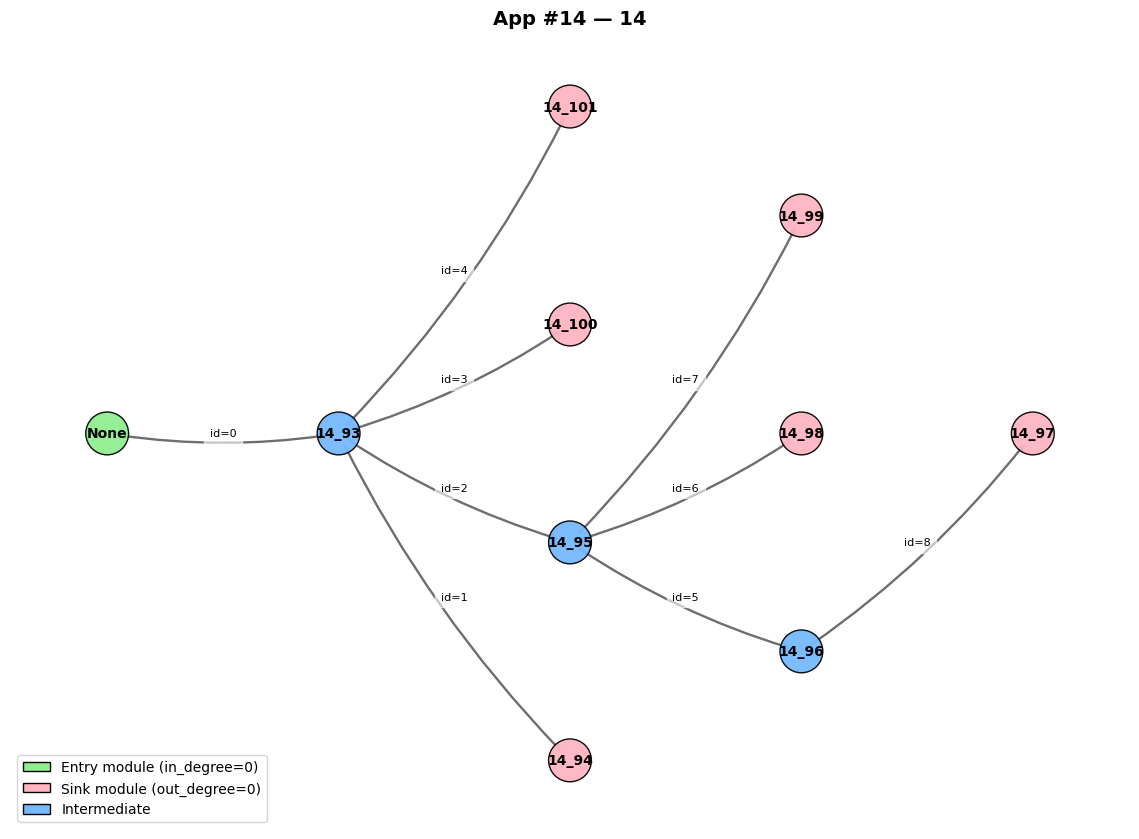

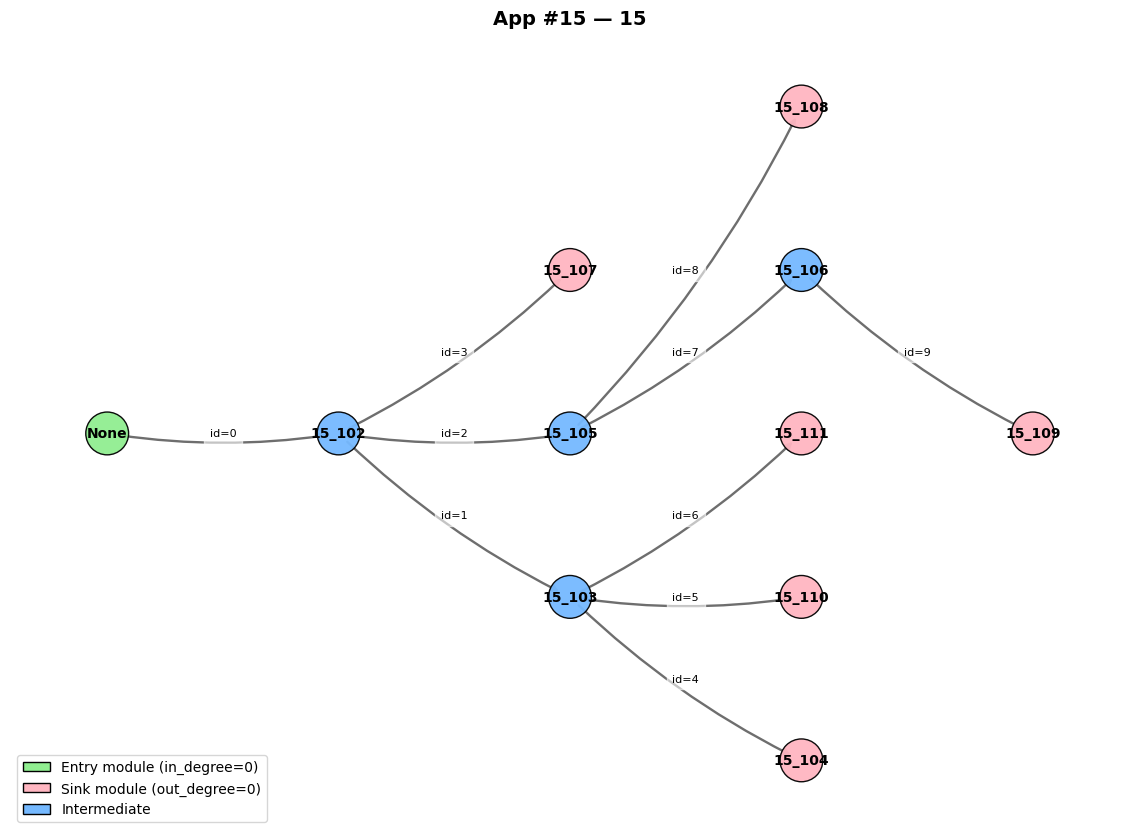

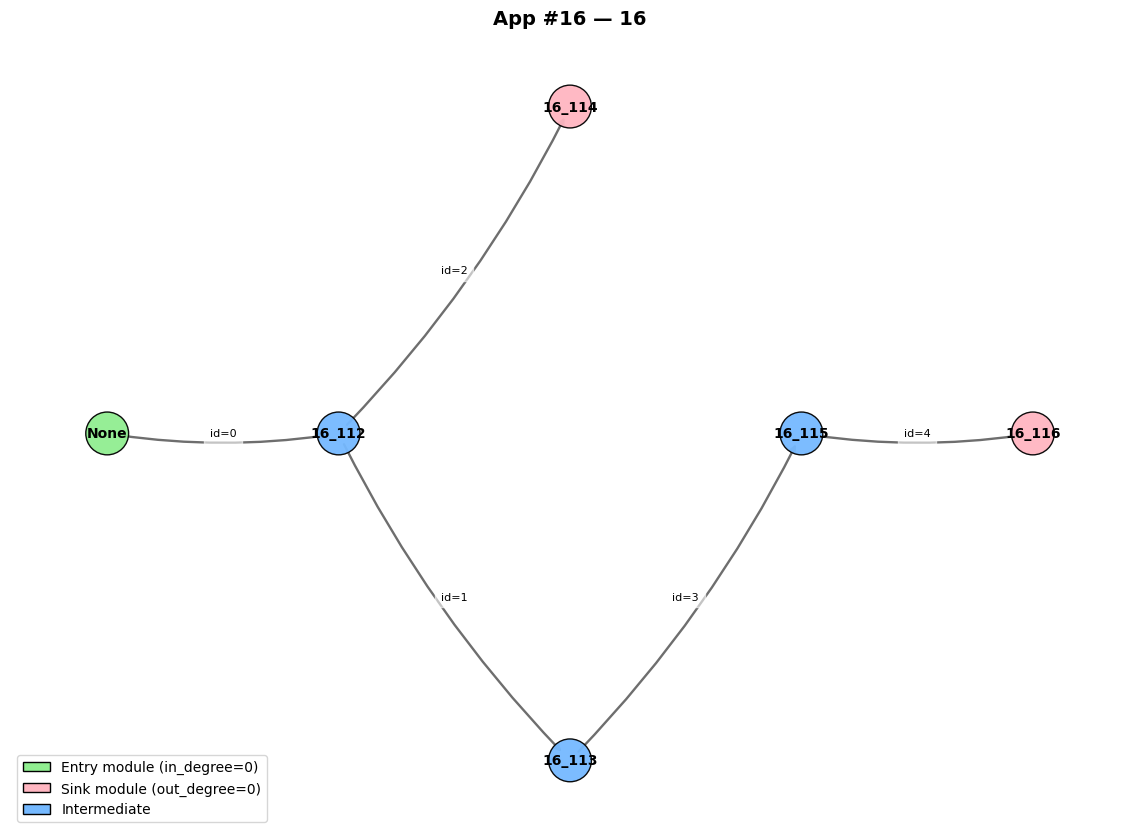

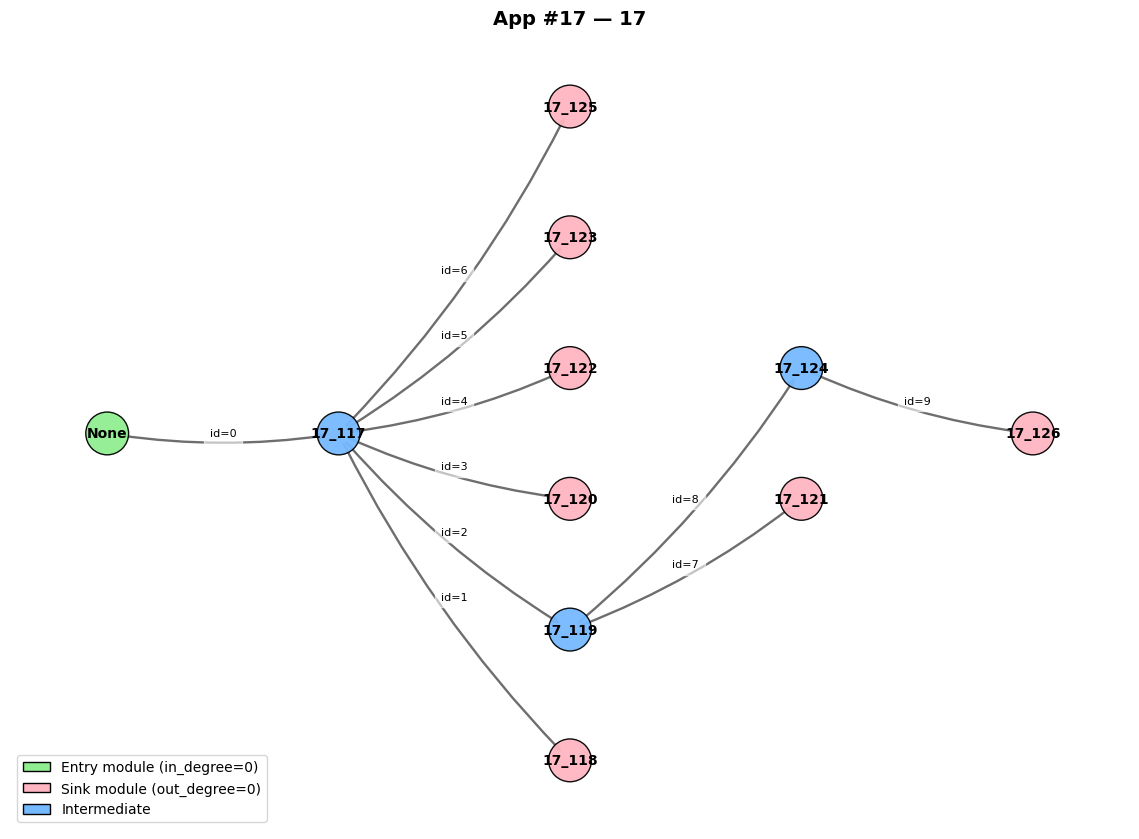

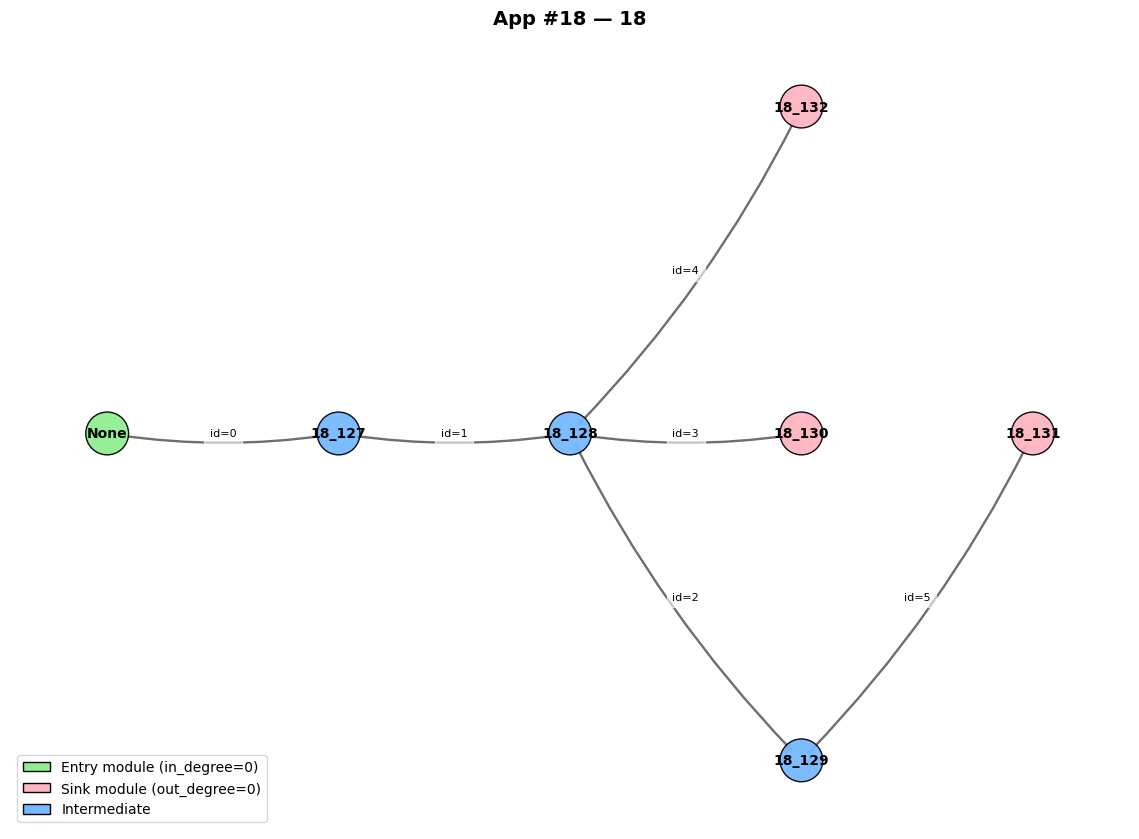

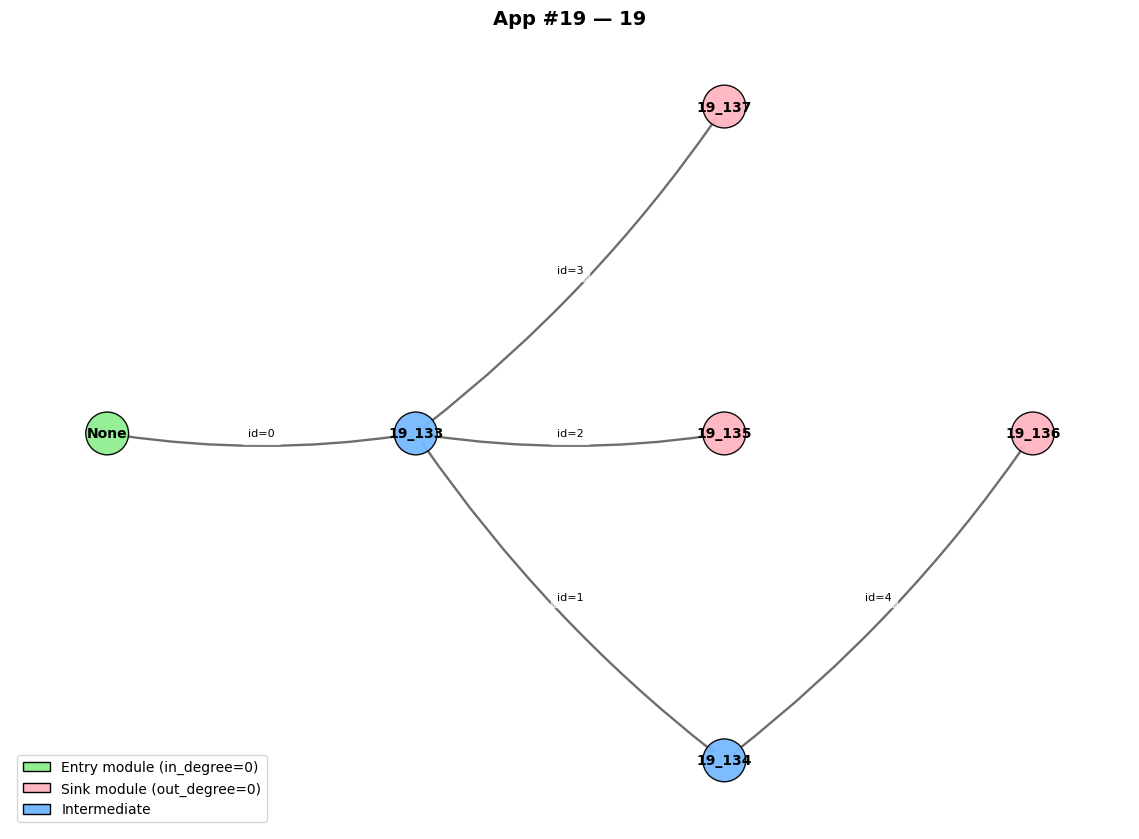

Graf aplikasi tersimpan:
- App #0 (0): /Users/adhitya/Project/exp/2. aplikasi/graph/app_0_0.png
- App #1 (1): /Users/adhitya/Project/exp/2. aplikasi/graph/app_1_1.png
- App #2 (2): /Users/adhitya/Project/exp/2. aplikasi/graph/app_2_2.png
- App #3 (3): /Users/adhitya/Project/exp/2. aplikasi/graph/app_3_3.png
- App #4 (4): /Users/adhitya/Project/exp/2. aplikasi/graph/app_4_4.png
- App #5 (5): /Users/adhitya/Project/exp/2. aplikasi/graph/app_5_5.png
- App #6 (6): /Users/adhitya/Project/exp/2. aplikasi/graph/app_6_6.png
- App #7 (7): /Users/adhitya/Project/exp/2. aplikasi/graph/app_7_7.png
- App #8 (8): /Users/adhitya/Project/exp/2. aplikasi/graph/app_8_8.png
- App #9 (9): /Users/adhitya/Project/exp/2. aplikasi/graph/app_9_9.png
- App #10 (10): /Users/adhitya/Project/exp/2. aplikasi/graph/app_10_10.png
- App #11 (11): /Users/adhitya/Project/exp/2. aplikasi/graph/app_11_11.png
- App #12 (12): /Users/adhitya/Project/exp/2. aplikasi/graph/app_12_12.png
- App #13 (13): /Users/adhitya/Project/e

In [8]:
SHOW_EDGE_LABELS   = True           # True/False: tampilkan label edge
EDGE_LABEL_MODE    = "id"           # "id" | "brief" | "full"
SHOW_NODE_DETAILS  = False          # True = judul node berisi 'Modul\nRAM/MIPS'
FIGSIZE            = (11.5, 8.5)
H_SPACING, V_SPACING = 1.9, 1.7     # jarak antar-layer & antar-node per layer
CURVE              = 0.08           # kelengkungan edge (supaya tidak menimpa)

# ========= HELPERS =========
def get_src(msg):
    return msg.get("src") or msg.get("s") or msg.get("source") or msg.get("from")
def get_dst(msg):
    return msg.get("dst") or msg.get("d") or msg.get("destination") or msg.get("to")

def build_app_graph(app):
    """Bangun graf terarah: node=modul, edge=message."""
    G = nx.DiGraph()
    # nodes (modules)
    for m in app.get("module", []):
        name = m.get("name", str(m["id"]))
        G.add_node(
            name,
            id=m["id"],
            RAM=m.get("RAM", 0),
            MIPS=m.get("MIPS", 0),
        )
    # edges (messages)
    for msg in app.get("message", []):
        src, dst = get_src(msg), get_dst(msg)
        if src is None or dst is None:
            continue
        G.add_edge(
            src, dst,
            msg_id=msg.get("id", None),
            bytes=msg.get("bytes", None),
            instructions=msg.get("instructions", None),
        )
    return G

def layered_pos(G: nx.DiGraph):
    """
    Posisi berlapis (kiri->kanan) via topological_generations.
    Fallback: layering approx berbasis BFS dari entry jika graf bersiklus.
    """
    try:
        gens = list(nx.topological_generations(G))  # error jika ada siklus
    except nx.NetworkXUnfeasible:
        entries = [n for n in G.nodes if G.in_degree(n) == 0] or [next(iter(G.nodes))]
        layers, visited, frontier = [], set(), list(entries)
        while frontier:
            layer, next_frontier = [], []
            for u in frontier:
                if u in visited: 
                    continue
                visited.add(u); layer.append(u)
                for v in G.successors(u):
                    if v not in visited:
                        next_frontier.append(v)
            layers.append(layer)
            frontier = next_frontier
        gens = layers

    pos = {}
    for x, layer_nodes in enumerate(gens):
        n = len(layer_nodes)
        if n == 1:
            ys = [0.0]
        else:
            start = - (n - 1) * V_SPACING / 2.0
            ys = [start + i * V_SPACING for i in range(n)]
        for y, node in zip(ys, layer_nodes):
            pos[node] = (x * H_SPACING, y)
    return pos

def edge_label_text(d, mode="id"):
    if mode == "id":
        return f"id={d.get('msg_id')}" if d.get("msg_id") is not None else ""
    elif mode == "brief":
        parts = []
        if d.get("msg_id") is not None: parts.append(f"id={d['msg_id']}")
        if d.get("bytes") is not None:  parts.append(f"B={d['bytes']}")
        return ", ".join(parts)
    else:  # "full"
        parts = []
        if d.get("msg_id") is not None:       parts.append(f"id={d['msg_id']}")
        if d.get("bytes") is not None:        parts.append(f"bytes={d['bytes']}")
        if d.get("instructions") is not None: parts.append(f"instr={d['instructions']}")
        return ", ".join(parts)

def draw_app_graph(app, out_basepath):
    """Render satu aplikasi menjadi PNG; return path PNG."""
    G = build_app_graph(app)
    if len(G) == 0:
        return None

    pos = layered_pos(G)

    # Entry & sink detection
    entries = [n for n in G.nodes if G.in_degree(n) == 0]
    sinks   = [n for n in G.nodes if G.out_degree(n) == 0]

    # Node styles: warna by role, size ~ log(MIPS)
    node_colors, node_sizes, labels = [], [], {}
    for n, attrs in G.nodes(data=True):
        # warna
        if n in entries:
            color = "#90EE90"  # hijau muda (entry)
        elif n in sinks:
            color = "#FFB6C1"  # merah muda (sink)
        else:
            color = "#75B9FF"  # biru (intermediate)
        node_colors.append(color)

        # size
        mips = float(attrs.get("MIPS", 0) or 0)
        size = 950 if mips <= 0 else 950 + 0.6 * math.log10(1 + mips) * 750
        node_sizes.append(size)

        # label
        if SHOW_NODE_DETAILS:
            labels[n] = f"{n}\nRAM={attrs.get('RAM',0)}, MIPS={attrs.get('MIPS',0)}"
        else:
            labels[n] = n

    plt.figure(figsize=FIGSIZE)

    nx.draw_networkx_nodes(
        G, pos, node_color=node_colors, node_size=node_sizes,
        alpha=0.95, linewidths=1.0, edgecolors="black"
    )
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=10, font_weight="bold")

    nx.draw_networkx_edges(
        G, pos, edge_color="#666666", arrows=True, width=1.7, alpha=0.95,
        connectionstyle=f"arc3,rad={CURVE}"
    )

    if SHOW_EDGE_LABELS:
        e_labels = { (u,v): edge_label_text(d, EDGE_LABEL_MODE) for u,v,d in G.edges(data=True) }
        nx.draw_networkx_edge_labels(
            G, pos, edge_labels=e_labels, font_size=8, rotate=False,
            bbox=dict(alpha=0.6, color="white")
        )

    # Legend
    legend_elems = [
        Patch(facecolor="#90EE90", edgecolor="black", label="Entry module (in_degree=0)"),
        Patch(facecolor="#FFB6C1", edgecolor="black", label="Sink module (out_degree=0)"),
        Patch(facecolor="#75B9FF", edgecolor="black", label="Intermediate"),
    ]
    plt.legend(handles=legend_elems, loc="lower left")
    plt.title(f"App #{app.get('id')} — {app.get('name', str(app.get('id')))}",
              fontsize=14, fontweight="bold", pad=10)
    plt.axis("off")
    plt.tight_layout()

    png_path = out_basepath + ".png"
    plt.savefig(png_path, dpi=220, bbox_inches="tight")
    plt.show()
    return png_path

save_dir = os.path.join(data_path, "2. aplikasi", "graph")
os.makedirs(save_dir, exist_ok=True)

# ========= RUN: render semua app =========
saved = []
for app in app_definition:
    app_id   = app["id"]
    app_name = app.get("name", str(app_id))
    safe = "".join(c if c.isalnum() or c in (" ", "_", "-") else "_" for c in app_name).strip()
    out_basepath = os.path.join(save_dir, f"app_{app_id}_{safe}")
    path = draw_app_graph(app, out_basepath)
    if path:
        saved.append((app_id, app_name, path))

print("Graf aplikasi tersimpan:")
for app_id, app_name, path in saved:
    print(f"- App #{app_id} ({app_name}): {path}")


## 3. User Definition

### 3.1 Statisik User

In [9]:
# --- LOAD ---
with open(data_path + 'data/usersDefinition.json', 'r') as file:
    users_def = json.load(file)

# Struktur: {"sources": [ {app, message, id_resource, lambda}, ... ]}
sources = users_def.get("sources", [])
users_df = pd.DataFrame(sources)

# Validasi kolom minimal
required_cols = {"app", "message", "id_resource", "lambda"}
missing = required_cols - set(users_df.columns)
if missing:
    raise ValueError(f"Kolom wajib hilang di usersDefinition.json: {missing}")

# Pastikan tipe
users_df["lambda"] = pd.to_numeric(users_df["lambda"], errors="coerce")  # ms
users_df["id_resource"] = pd.to_numeric(users_df["id_resource"], errors="coerce").astype("Int64")

# ================== REKAP DASAR ==================
total_users = len(users_df)
total_apps  = users_df["app"].nunique()
total_gw    = users_df["id_resource"].nunique()

print(f"Jumlah total user: {total_users}")
print(f"Jumlah aplikasi yang terhubung dengan user: {total_apps}")
print(f"Jumlah gateway (id_resource) yang dipakai user: {total_gw}")


Jumlah total user: 64
Jumlah aplikasi yang terhubung dengan user: 20
Jumlah gateway (id_resource) yang dipakai user: 24


In [10]:
import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ================== CONFIG ==================
data_path = "/Users/adhitya/Project/exp/"  # ganti sesuai foldermu
users_path   = os.path.join(data_path, "data", "usersDefinition.json")
network_path = os.path.join(data_path, "data", "networkDefinition.json")

save_dir  = os.path.join(data_path, "3. user")
graph_dir = os.path.join(save_dir, "graph")
os.makedirs(save_dir, exist_ok=True)
os.makedirs(graph_dir, exist_ok=True)

# ================== LOAD ==================
with open(users_path, "r") as f:
    users_def = json.load(f)
with open(network_path, "r") as f:
    net_def = json.load(f)

users_df = pd.DataFrame(users_def.get("sources", []))
entities_df = pd.DataFrame(net_def["entity"])

# Validasi minimal
required_cols = {"app", "message", "id_resource", "lambda"}
missing = required_cols - set(users_df.columns)
if missing:
    raise ValueError(f"Kolom wajib hilang di usersDefinition.json: {missing}")

# Normalisasi tipe
users_df["app"] = users_df["app"].astype(str)
users_df["lambda"] = pd.to_numeric(users_df["lambda"], errors="coerce")   # ms
users_df["id_resource"] = pd.to_numeric(users_df["id_resource"], errors="coerce").astype("Int64")
users_df["rps"] = users_df["lambda"].apply(lambda x: 1000.0/float(x) if pd.notna(x) and float(x) > 0 else float("nan"))

# ================== DEFINISI GATEWAY: HANYA FG ==================
entities_df["type"] = entities_df["type"].astype(str).str.upper()
GATEWAY_TYPES = {"FG"}            # <--- penting: hanya FG dianggap gateway
gateway_df = entities_df[entities_df["type"].isin(GATEWAY_TYPES)].copy()

# Daftar FG (defined), used FG (muncul di users), dan unused FG
fg_ids = sorted(set(gateway_df["id"].astype(int).tolist()))
used_fg_ids = sorted(set(users_df["id_resource"].dropna().astype(int).tolist()) & set(fg_ids))
unused_fg_ids = [g for g in fg_ids if g not in used_fg_ids]

print("=== FG gateways digunakan user (ID) ===")
print(used_fg_ids)
print("\n=== FG gateways TIDAK digunakan user (ID) ===")
print(unused_fg_ids)

# ================== REKAP (pastikan kolom num_users TERBENTUK) ==================
# Rekap per aplikasi (semua user)
users_per_app = users_df.groupby("app").size().reset_index(name="num_users")  # <-- kolom 'num_users' dijamin ada

lambda_stats  = users_df.groupby("app")["lambda"].agg(
    num_users="count", avg_lambda_ms="mean", min_lambda_ms="min", max_lambda_ms="max"
).reset_index()

rps_per_app   = users_df.groupby("app")["rps"].sum(min_count=1).reset_index(name="sum_rps")

app_summary   = users_per_app.merge(lambda_stats, on="app", how="left").merge(rps_per_app, on="app", how="left")

# Rekap per gateway: FILTER ke FG SAJA supaya konsisten dengan definisi gateway
users_df_fg = users_df[users_df["id_resource"].isin(fg_ids)].copy()

users_per_gw = users_df_fg.groupby("id_resource").size().reset_index(name="num_users")  # <-- kolom 'num_users' ada
lambda_per_gw = users_df_fg.groupby("id_resource")["lambda"].mean().reset_index(name="avg_lambda_ms")
rps_per_gw    = users_df_fg.groupby("id_resource")["rps"].sum(min_count=1).reset_index(name="sum_rps")

gw_summary    = users_per_gw.merge(lambda_per_gw, on="id_resource", how="left").merge(rps_per_gw, on="id_resource", how="left")

# Matrix gateway(FG) x app (untuk stacked bar)
gw_app = users_df_fg.groupby(["id_resource", "app"]).size().reset_index(name="num_users")

# ================== SIMPAN CSV (sesuai ketentuanmu) ==================
raw_csv         = os.path.join(save_dir, "users_raw.csv")
app_summary_csv = os.path.join(save_dir, "users_app_summary.csv")
gw_summary_csv  = os.path.join(save_dir, "users_gateway_summary.csv")
gw_app_csv      = os.path.join(save_dir, "users_gateway_app_matrix.csv")

users_df.to_csv(raw_csv, index=False)
app_summary.to_csv(app_summary_csv, index=False)
gw_summary.to_csv(gw_summary_csv, index=False)
gw_app.to_csv(gw_app_csv, index=False)

print(f"\n[OK] Simpan: {raw_csv}")
print(f"[OK] Simpan: {app_summary_csv}")
print(f"[OK] Simpan: {gw_summary_csv}")
print(f"[OK] Simpan: {gw_app_csv}")

# ================== GRAFIK BAR (tanpa heatmap) ==================
# 1) jumlah user per aplikasi
plt.figure(figsize=(10,6))
plt.bar(app_summary["app"].astype(str), app_summary["num_users"])
plt.xlabel("App"); plt.ylabel("Jumlah User")
plt.title("Distribusi User per Aplikasi")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
p1 = os.path.join(graph_dir, "users_per_app.png")
plt.savefig(p1, dpi=160, bbox_inches="tight"); plt.show()

# 2) jumlah user per FG gateway
plt.figure(figsize=(10,6))
plt.bar(gw_summary["id_resource"].astype(str), gw_summary["num_users"])
plt.xlabel("FG Gateway (id_resource)"); plt.ylabel("Jumlah User")
plt.title("Distribusi User per FG Gateway")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
p2 = os.path.join(graph_dir, "users_per_fg_gateway.png")
plt.savefig(p2, dpi=160, bbox_inches="tight"); plt.show()

# 3) stacked bar: komposisi user per FG gateway menurut app
pivot = gw_app.pivot_table(index="id_resource", columns="app", values="num_users", fill_value=0).sort_index()
plt.figure(figsize=(max(10, 0.5 * pivot.shape[0] + 6), 8))
bottom = np.zeros(pivot.shape[0], dtype=float)
xlabels = pivot.index.astype(str)

for col in pivot.columns:
    vals = pivot[col].values.astype(float)
    plt.bar(xlabels, vals, bottom=bottom, label=str(col))
    bottom += vals

plt.xlabel("FG Gateway (id_resource)")
plt.ylabel("Jumlah User")
plt.title("Komposisi User per FG Gateway (Stacked by App)")
plt.xticks(rotation=45, ha="right")

# tampilkan legend kalau jumlah app tidak kebanyakan
if len(pivot.columns) <= 15:
    plt.legend(title="App", bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
p3 = os.path.join(graph_dir, "stacked_users_per_fg_gateway_by_app.png")
plt.savefig(p3, dpi=160, bbox_inches="tight"); plt.show()


=== FG gateways digunakan user (ID) ===
[25, 31, 32, 37, 41, 44, 47, 49, 54, 56, 57, 73, 74, 76, 77, 79, 80, 85, 86, 89, 90, 93, 94, 99]

=== FG gateways TIDAK digunakan user (ID) ===
[7]

[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_raw.csv
[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_app_summary.csv
[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_gateway_summary.csv
[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_gateway_app_matrix.csv


KeyError: 'num_users'

<Figure size 1000x600 with 0 Axes>

=== FG gateways digunakan user (ID) ===
[25, 31, 32, 37, 41, 44, 47, 49, 54, 56, 57, 73, 74, 76, 77, 79, 80, 85, 86, 89, 90, 93, 94, 99]

=== FG gateways TIDAK digunakan user (ID) ===
[7]

Ringkas: FG defined = 25, used = 24, unused = 1

[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_raw.csv
[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_app_summary.csv
[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_gateway_summary.csv
[OK] Simpan: /Users/adhitya/Project/exp/3. user/users_gateway_app_matrix.csv


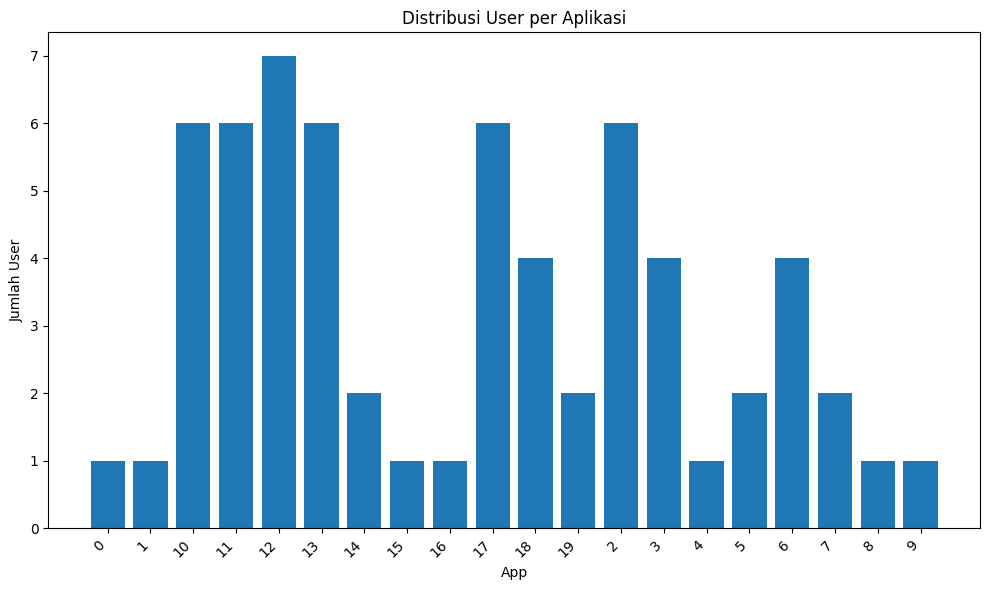

[OK] Grafik: /Users/adhitya/Project/exp/3. user/graph/users_per_app.png


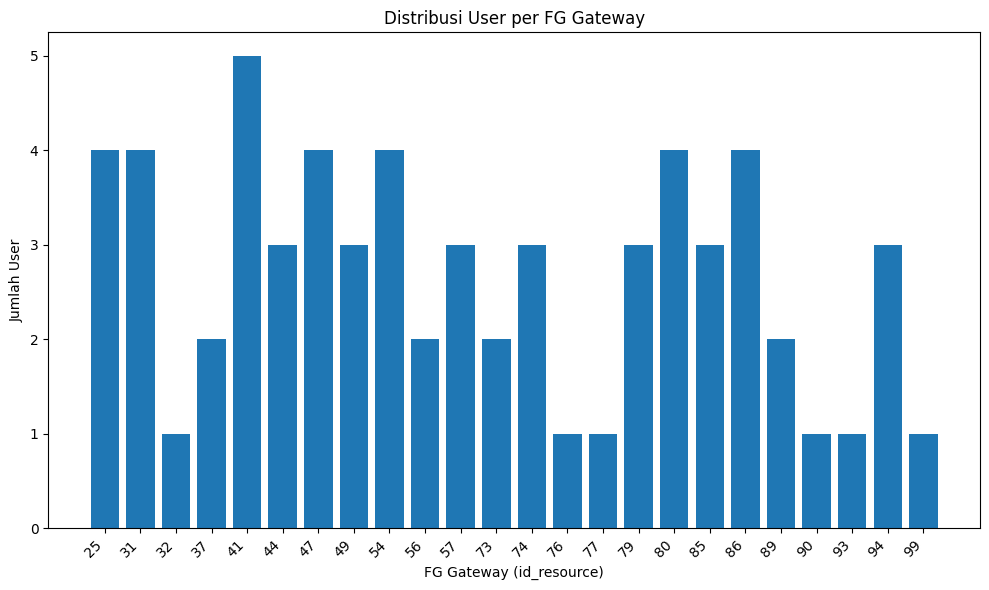

[OK] Grafik: /Users/adhitya/Project/exp/3. user/graph/users_per_fg_gateway.png


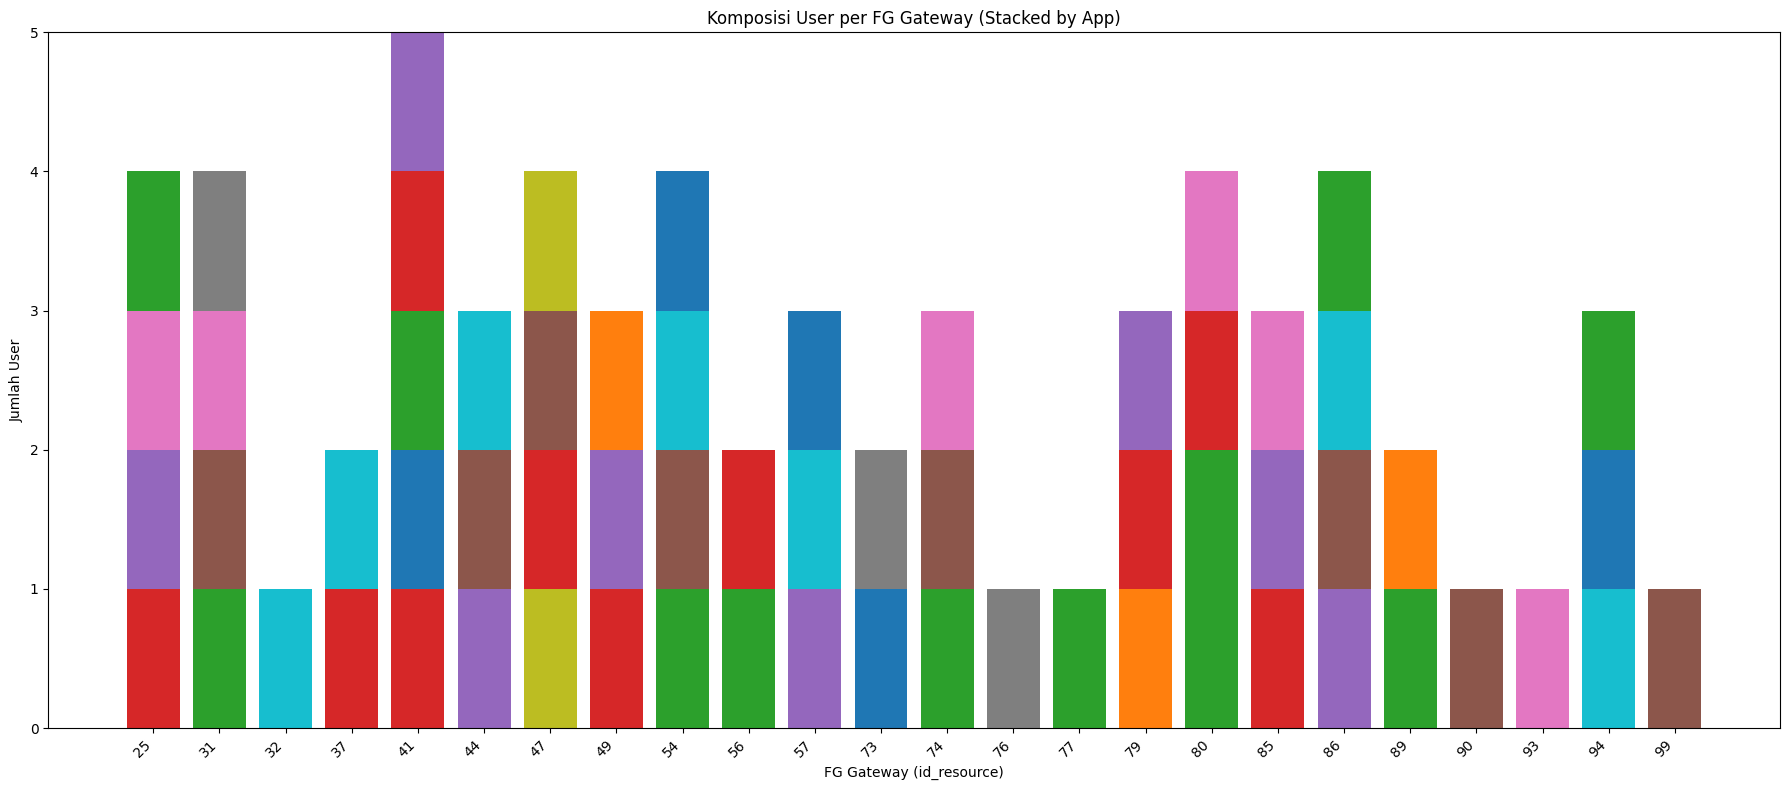

[OK] Grafik: /Users/adhitya/Project/exp/3. user/graph/stacked_users_per_fg_gateway_by_app.png


In [11]:
import os, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ================== CONFIG ==================
data_path = "/Users/adhitya/Project/exp/"  # <<< ganti sesuai foldermu
users_path   = os.path.join(data_path, "data", "usersDefinition.json")
network_path = os.path.join(data_path, "data", "networkDefinition.json")

save_dir  = os.path.join(data_path, "3. user")
graph_dir = os.path.join(save_dir, "graph")
os.makedirs(save_dir, exist_ok=True)
os.makedirs(graph_dir, exist_ok=True)

# ================== LOAD ==================
with open(users_path, "r") as f:
    users_def = json.load(f)
with open(network_path, "r") as f:
    net_def = json.load(f)

users_df = pd.DataFrame(users_def.get("sources", []))
entities_df = pd.DataFrame(net_def["entity"])

# Validasi minimal
required_cols = {"app", "message", "id_resource", "lambda"}
missing = required_cols - set(users_df.columns)
if missing:
    raise ValueError(f"Kolom wajib hilang di usersDefinition.json: {missing}")

# Normalisasi tipe
users_df["app"] = users_df["app"].astype(str)
users_df["lambda"] = pd.to_numeric(users_df["lambda"], errors="coerce")   # ms
users_df["id_resource"] = pd.to_numeric(users_df["id_resource"], errors="coerce").astype("Int64")
users_df["rps"] = users_df["lambda"].apply(lambda x: 1000.0/float(x) if pd.notna(x) and float(x) > 0 else float("nan"))

# ================== DEFINISI GATEWAY: HANYA FG ==================
entities_df["type"] = entities_df["type"].astype(str).str.upper()
GATEWAY_TYPES = {"FG"}  # penting: hanya FG sebagai gateway

gateway_df = entities_df[entities_df["type"].isin(GATEWAY_TYPES)].copy()
fg_ids = sorted(set(gateway_df["id"].astype(int).tolist()))

used_fg_ids = sorted(set(users_df["id_resource"].dropna().astype(int).tolist()) & set(fg_ids))
unused_fg_ids = [g for g in fg_ids if g not in used_fg_ids]

print("=== FG gateways digunakan user (ID) ===")
print(used_fg_ids)
print("\n=== FG gateways TIDAK digunakan user (ID) ===")
print(unused_fg_ids)
print(f"\nRingkas: FG defined = {len(fg_ids)}, used = {len(used_fg_ids)}, unused = {len(unused_fg_ids)}")

# ================== REKAP PER APLIKASI (hindari tabrakan kolom) ==================
# jumlah user per app
users_per_app = users_df.groupby("app").size().reset_index(name="num_users")

# statistik lambda per app (pakai nama berbeda agar tidak bentrok)
lambda_stats = users_df.groupby("app")["lambda"].agg(
    n_records="count",              # bukan 'num_users'
    avg_lambda_ms="mean",
    min_lambda_ms="min",
    max_lambda_ms="max"
).reset_index()

# total RPS per app
rps_per_app = users_df.groupby("app")["rps"].sum(min_count=1).reset_index(name="sum_rps")

# gabung
app_summary = (
    users_per_app
    .merge(lambda_stats, on="app", how="left")
    .merge(rps_per_app,   on="app", how="left")
)

# ================== REKAP PER FG GATEWAY ==================
users_df_fg = users_df[users_df["id_resource"].isin(fg_ids)].copy()

users_per_gw = users_df_fg.groupby("id_resource").size().reset_index(name="num_users")
lambda_per_gw = users_df_fg.groupby("id_resource")["lambda"].mean().reset_index(name="avg_lambda_ms")
rps_per_gw    = users_df_fg.groupby("id_resource")["rps"].sum(min_count=1).reset_index(name="sum_rps")

gw_summary = (
    users_per_gw
    .merge(lambda_per_gw, on="id_resource", how="left")
    .merge(rps_per_gw,    on="id_resource", how="left")
)

# Matrix gateway(FG) × app (untuk stacked bar)
gw_app = users_df_fg.groupby(["id_resource", "app"]).size().reset_index(name="num_users")

# ================== SIMPAN CSV (sesuai ketentuan) ==================
raw_csv         = os.path.join(save_dir, "users_raw.csv")
app_summary_csv = os.path.join(save_dir, "users_app_summary.csv")
gw_summary_csv  = os.path.join(save_dir, "users_gateway_summary.csv")
gw_app_csv      = os.path.join(save_dir, "users_gateway_app_matrix.csv")

users_df.to_csv(raw_csv, index=False)
app_summary.to_csv(app_summary_csv, index=False)
gw_summary.to_csv(gw_summary_csv, index=False)
gw_app.to_csv(gw_app_csv, index=False)

print(f"\n[OK] Simpan: {raw_csv}")
print(f"[OK] Simpan: {app_summary_csv}")
print(f"[OK] Simpan: {gw_summary_csv}")
print(f"[OK] Simpan: {gw_app_csv}")

# ================== GRAFIK (tanpa heatmap) ==================
# 1) jumlah user per aplikasi
plt.figure(figsize=(10,6))
plt.bar(app_summary["app"].astype(str), app_summary["num_users"])
plt.xlabel("App"); plt.ylabel("Jumlah User")
plt.title("Distribusi User per Aplikasi")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
p1 = os.path.join(graph_dir, "users_per_app.png")
plt.savefig(p1, dpi=160, bbox_inches="tight"); plt.show()
print(f"[OK] Grafik: {p1}")

# 2) jumlah user per FG gateway
plt.figure(figsize=(10,6))
plt.bar(gw_summary["id_resource"].astype(str), gw_summary["num_users"])
plt.xlabel("FG Gateway (id_resource)"); plt.ylabel("Jumlah User")
plt.title("Distribusi User per FG Gateway")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
p2 = os.path.join(graph_dir, "users_per_fg_gateway.png")
plt.savefig(p2, dpi=160, bbox_inches="tight"); plt.show()
print(f"[OK] Grafik: {p2}")

# 3) stacked bar: komposisi user per FG gateway menurut app
pivot = gw_app.pivot_table(index="id_resource", columns="app", values="num_users", fill_value=0).sort_index()
plt.figure(figsize=(max(10, 0.5 * pivot.shape[0] + 6), 8))
bottom = np.zeros(pivot.shape[0], dtype=float)
xlabels = pivot.index.astype(str)

for col in pivot.columns:
    vals = pivot[col].values.astype(float)
    plt.bar(xlabels, vals, bottom=bottom, label=str(col))
    bottom += vals

plt.xlabel("FG Gateway (id_resource)")
plt.ylabel("Jumlah User")
plt.title("Komposisi User per FG Gateway (Stacked by App)")
plt.xticks(rotation=45, ha="right")

# tampilkan legend kalau jumlah app tidak berlebihan
if len(pivot.columns) <= 15:
    plt.legend(title="App", bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0.)
plt.tight_layout()
p3 = os.path.join(graph_dir, "stacked_users_per_fg_gateway_by_app.png")
plt.savefig(p3, dpi=160, bbox_inches="tight"); plt.show()
print(f"[OK] Grafik: {p3}")


In [ ]:
# ================== METRIK PER APLIKASI ==================
# jumlah user per app
users_per_app = users_df.groupby("app").size().reset_index(name="num_users")

# statistik lambda per app (ms)
lambda_stats = users_df.groupby("app")["lambda"].agg(
    num_users="count",
    avg_lambda_ms="mean",
    min_lambda_ms="min",
    max_lambda_ms="max"
).reset_index()

# estimasi RPS per user = 1000 / lambda_ms (hindari lambda=0)
def to_rps(lmb):
    try:
        lmb = float(lmb)
        return 1000.0 / lmb if lmb > 0 else float("nan")
    except:
        return float("nan")

users_df["rps"] = users_df["lambda"].apply(to_rps)
rps_per_app = users_df.groupby("app")["rps"].sum().reset_index(name="sum_rps")

# gabungkan ringkasan app
app_summary = users_per_app.merge(lambda_stats, on="app", how="left").merge(rps_per_app, on="app", how="left")

# ================== METRIK PER GATEWAY ==================
users_per_gw = users_df.groupby("id_resource").size().reset_index(name="num_users")
lambda_per_gw = users_df.groupby("id_resource")["lambda"].mean().reset_index(name="avg_lambda_ms")
rps_per_gw = users_df.groupby("id_resource")["rps"].sum().reset_index(name="sum_rps")
gw_summary = users_per_gw.merge(lambda_per_gw, on="id_resource", how="left").merge(rps_per_gw, on="id_resource", how="left")

# ================== (OPSIONAL) ESTIMASI TRAFFIC BYTES/S ==================
# butuh appDefinition untuk dapat 'bytes' pesan entry (message yang dipakai user)
traffic_app = pd.DataFrame()
try:
    with open(apps_json_path, "r") as f:
        apps_def = json.load(f)

    # buat index: (app_name, message_name) -> bytes
    rows = []
    for app in apps_def:
        app_name = app.get("name", str(app.get("id")))
        for msg in app.get("message", []):
            msg_name = msg.get("name") or msg.get("id")  # tergantung struktur
            # fallback: kalau tidak ada 'name', kadang message terindeks via (src,dst)
            rows.append({
                "app": app_name,
                "message": msg_name,
                "bytes": msg.get("bytes", float("nan"))
            })
    msg_df = pd.DataFrame(rows)
    # join ke users_df berdasarkan (app, message) jika ada kolom 'message' yang cocok
    if not msg_df.empty and "message" in users_df.columns:
        enriched = users_df.merge(msg_df, on=["app", "message"], how="left")
        # bytes/s = rps * bytes
        enriched["bytes_per_s"] = enriched["rps"] * pd.to_numeric(enriched["bytes"], errors="coerce")
        traffic_app = enriched.groupby("app")["bytes_per_s"].sum().reset_index(name="sum_bytes_per_s")
        # satukan ke ringkasan app
        app_summary = app_summary.merge(traffic_app, on="app", how="left")
except Exception as e:
    print(f"(Opsional) Estimasi traffic di-skip: {e}")

In [ ]:
# ================== SIMPAN CSV ==================
save_dir  = os.path.join(data_path, "3. user")
os.makedirs(save_dir, exist_ok=True)

users_csv        = os.path.join(save_dir, "users_raw.csv")
app_summary_csv  = os.path.join(save_dir, "users_app_summary.csv")
gw_summary_csv   = os.path.join(save_dir, "users_gateway_summary.csv")

users_df.to_csv(users_csv, index=False)
app_summary.to_csv(app_summary_csv, index=False)
gw_summary.to_csv(gw_summary_csv, index=False)

print(f"[OK] simpan: {users_csv}")
print(f"[OK] simpan: {app_summary_csv}")
print(f"[OK] simpan: {gw_summary_csv}")

[OK] simpan: /Users/adhitya/Project/exp/3. user/users_raw.csv
[OK] simpan: /Users/adhitya/Project/exp/3. user/users_app_summary.csv
[OK] simpan: /Users/adhitya/Project/exp/3. user/users_gateway_summary.csv


In [ ]:
# ================== GRAFIK ==================
# 1) Users per App
plt.figure(figsize=(10,6))
plt.bar(app_summary["app"].astype(str), app_summary["num_users"])
plt.xlabel("App")
plt.ylabel("Jumlah User")
plt.title("Distribusi User per Aplikasi")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
path1 = os.path.join(graph_dir, "users_per_app.png")
plt.savefig(path1, dpi=150, bbox_inches="tight")
plt.show()

# 2) Sum RPS per App
plt.figure(figsize=(10,6))
plt.bar(app_summary["app"].astype(str), app_summary["sum_rps"].fillna(0))
plt.xlabel("App")
plt.ylabel("Total RPS (∑ 1000/λ)")
plt.title("Estimasi Total Request Rate per Aplikasi")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
path2 = os.path.join(graph_dir, "sum_rps_per_app.png")
plt.savefig(path2, dpi=150, bbox_inches="tight")
plt.show()

# 3) Users per Gateway (id_resource)
plt.figure(figsize=(10,6))
plt.bar(gw_summary["id_resource"].astype(str), gw_summary["num_users"])
plt.xlabel("Gateway (id_resource)")
plt.ylabel("Jumlah User")
plt.title("Distribusi User per Gateway")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
path3 = os.path.join(graph_dir, "users_per_gateway.png")
plt.savefig(path3, dpi=150, bbox_inches="tight")
plt.show()

# 4) (Opsional) Traffic bytes/s per App (jika join berhasil)
if "sum_bytes_per_s" in app_summary.columns:
    plt.figure(figsize=(10,6))
    plt.bar(app_summary["app"].astype(str), app_summary["sum_bytes_per_s"].fillna(0))
    plt.xlabel("App")
    plt.ylabel("Total Traffic (bytes/s)")
    plt.title("Estimasi Total Traffic per Aplikasi (entry message)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    path4 = os.path.join(graph_dir, "traffic_bytes_per_s_per_app.png")
    plt.savefig(path4, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[OK] simpan grafik traffic: {path4}")



graph_dir = os.path.join(save_dir, "graph")
os.makedirs(graph_dir, exist_ok=True)

print("\nSelesai. Rekap & grafik tersimpan di:")
print(f"- {save_dir}")
print(f"- {graph_dir}")


KeyError: 'num_users'

<Figure size 1000x600 with 0 Axes>

In [ ]:
# --- LOAD ---
with open(data_path + 'data/usersDefinition.json', 'r') as file:
    usersDefinition = json.load(file)

# Ambil list of users
users = usersDefinition['sources']

# Buat DataFrame agar mudah analisis
df = pd.DataFrame(users)

# Hitung jumlah total user dan aplikasi
total_users = len(df)
total_apps = df['app'].nunique()

print("Jumlah total user:", total_users)
print("Jumlah aplikasi yang terhubung dengan user:", total_apps)

# Hitung gateway yang digunakan user
id_resources = set(df['id_resource'])
print(f"Request user berasal dari {len(id_resources)} gateway device, yaitu: {id_resources}")

# --- Distribusi user per aplikasi ---
users_per_app = df.groupby("app").size().reset_index(name="num_users")

plt.figure(figsize=(10,6))
plt.bar(users_per_app["app"].astype(str), users_per_app["num_users"])
plt.xlabel("App")
plt.ylabel("Jumlah User")
plt.title("Distribusi User per Aplikasi")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# --- Analisis lambda per aplikasi ---
lambda_stats = df.groupby("app")["lambda"].agg(
    num_users="count",
    avg_lambda="mean",
    min_lambda="min",
    max_lambda="max"
).reset_index()

print("\nStatistik Lambda per Aplikasi:")
print(lambda_stats)

# Plot rata-rata lambda per aplikasi
plt.figure(figsize=(10,6))
plt.bar(lambda_stats["app"].astype(str), lambda_stats["avg_lambda"])
plt.xlabel("App")
plt.ylabel("Rata-rata Lambda (ms)")
plt.title("Rata-rata Lambda per Aplikasi")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Extract app "0" data
app_0 = app_definition[0]  # First app in the list has id=0
print(f"App {app_0['name']} (ID: {app_0['id']})")
print(f"Deadline: {app_0['deadline']} ms")
print(f"Jumlah modules: {len(app_0['module'])}")
print(f"Jumlah messages: {len(app_0['message'])}")

# Create a directed graph for app "0"
app_graph = nx.DiGraph()

# Tambah nodes (modules) beserta atributnya
for module in app_0['module']:
    module_name = module['name']
    module_ram = module['RAM']
    app_graph.add_node(module_name, RAM=module_ram, type=module['type'])

# Tambah edges (messages) beserta atributnya
for message in app_0['message']:
    source = message['s']
    destination = message['d']
    
    # Kelola jika source-nya "None" (user/workload input)
    if source == "None":
        external_node = "USER_INPUT"
        if not app_graph.has_node(external_node):
            app_graph.add_node(external_node, RAM=0, type="EXTERNAL")
        source = external_node
    
    app_graph.add_edge(
        source, 
        destination,
        name=message['name'],
        instructions=message['instructions'],
        bytes=message['bytes'],
        message_id=message['id']
    )

# Tampilkan atribut dari node
print("\n=== NODE ATTRIBUTES ===")
for node, attrs in app_graph.nodes(data=True):
    print(f"{node}: {attrs}")

# Tampilkan atribut dari edge
print("\n=== EDGE ATTRIBUTES ===")
for source, dest, attrs in app_graph.edges(data=True):
    print(f"{source} -> {dest}: {attrs}")

In [ ]:
# Visualisasi graf untuk app "0"
plt.figure(figsize=(18, 10))

def create_hierarchical_layout(graph):
    """Create a hierarchical layout showing the directed flow"""
    pos = {}
    layers = {}
    
    external_nodes = [n for n, attr in graph.nodes(data=True) if attr['type'] == 'EXTERNAL']
    if external_nodes:
        layers[0] = external_nodes
        pos[external_nodes[0]] = (0, 0)
    
    entry_points = []
    for node in graph.nodes():
        if graph.in_degree(node) == 1:
            predecessors = list(graph.predecessors(node))
            if predecessors and graph.nodes[predecessors[0]]['type'] == 'EXTERNAL':
                entry_points.append(node)
    
    if entry_points:
        layers[1] = entry_points
        for i, node in enumerate(entry_points):
            pos[node] = (2, i * 0.4)
    
    remaining_nodes = [n for n in graph.nodes() if n not in external_nodes + entry_points]
    
    distance_groups = {}
    for node in remaining_nodes:
        min_dist = float('inf')
        for entry in entry_points:
            if nx.has_path(graph, entry, node):
                dist = nx.shortest_path_length(graph, entry, node)
                min_dist = min(min_dist, dist)
        
        if min_dist == float('inf'):
            min_dist = 0  # Isolated nodes
        
        if min_dist not in distance_groups:
            distance_groups[min_dist] = []
        distance_groups[min_dist].append(node)
    
    # Posisi module
    for dist, nodes in distance_groups.items():
        layer_x = (dist + 1) * 2
        layer_y_start = -(len(nodes) - 1) * 0.5 / 2 
        
        for i, node in enumerate(nodes):
            pos[node] = (layer_x, layer_y_start + i * 0.5)
    
    return pos

pos = create_hierarchical_layout(app_graph)

module_nodes = [node for node, attrs in app_graph.nodes(data=True) if attrs['type'] == 'MODULE']
external_nodes = [node for node, attrs in app_graph.nodes(data=True) if attrs['type'] == 'EXTERNAL']

node_colors = []
node_sizes = []
for node in app_graph.nodes():
    attrs = app_graph.nodes[node]
    if attrs['type'] == 'EXTERNAL':
        node_colors.append('red')
        node_sizes.append(1500)  # Ukuran node user/workload
    else:
        node_colors.append('orange')
        node_sizes.append(1200)  # Ukuran node module

# Draw nodes
nx.draw_networkx_nodes(app_graph, pos, 
                      node_color=node_colors, 
                      node_size=node_sizes,
                      alpha=0.8)

# Draw edges with different widths based on bytes
edge_widths = []
for source, dest, attrs in app_graph.edges(data=True):
    # Normalize bytes to reasonable edge width (1-5)
    normalized_width = 1 + (attrs['bytes'] / 1000000) * 2  # Scale to 1-5 range
    edge_widths.append(min(normalized_width, 5))

nx.draw_networkx_edges(app_graph, pos, 
                      width=edge_widths,
                      edge_color='gray',
                      alpha=0.6,
                      arrows=True,
                      arrowsize=20,
                      arrowstyle='->')

# Draw labels with larger font (exclude USER_INPUT)
labels_to_draw = {node: node for node in app_graph.nodes() if node != 'USER_INPUT'}
nx.draw_networkx_labels(app_graph, pos, labels=labels_to_draw, font_size=14, font_weight='bold', font_color='black')

# Add edge labels with only message names (larger font)
edge_labels = {}
for source, dest, attrs in app_graph.edges(data=True):
    edge_labels[(source, dest)] = attrs['name']

nx.draw_networkx_edge_labels(app_graph, pos, edge_labels, font_size=12, font_weight='bold')

plt.title(f"Application {app_0['name']}\nDeadline: {app_0['deadline']}ms", 
          fontsize=18, fontweight='bold', pad=20)

plt.axis('off')
plt.tight_layout()
plt.show()

## User/Workload Definition

In [ ]:
# Print summary statistics
print("\n=== APP 0 SUMMARY ===")
print(f"Deadline: {app_0['deadline']} ms")
print(f"Total modules: {len(module_nodes)}")
print(f"Total external inputs: {len(external_nodes)}")
print(f"Total edges (messages): {app_graph.number_of_edges()}")

print("\nRESOURCE REQUIREMENTS:")
# RAM distribution
ram_values = [attrs['RAM'] for node, attrs in app_graph.nodes(data=True) if attrs['type'] == 'MODULE']
print(f"• Total RAM: {sum(ram_values)} MB")
print(f"• RAM range: {min(ram_values)}-{max(ram_values)} MB per module")

# Message size statistics
message_sizes = [attrs['bytes'] for _, _, attrs in app_graph.edges(data=True)]
print(f"• Total message size: {sum(message_sizes)/1000000:.2f} MB")
print(f"• Average message size: {sum(message_sizes)/len(message_sizes)/1000:.2f} KB")

# Instructions statistics
instruction_counts = [attrs['instructions'] for _, _, attrs in app_graph.edges(data=True)]
print(f"• Total instructions: {sum(instruction_counts):,} instructions")
print(f"• Average instructions per message: {sum(instruction_counts)/len(instruction_counts):.0f}")

# Perhitungan latency

### Jumlah aplikasi 10

#### Partition

In [ ]:
import pandas as pd

df_link_10 = pd.read_csv('results/results_GA_1000000_link.csv')
display(df_link_10)

average_latency_10 = df_link_10['latency'].mean()
print(f"\nAverage latency: {average_latency_10:.6f} ms")

#### ILP

In [ ]:
import pandas as pd

df_link_ilp_10 = pd.read_csv('results/10/results_ILP_1000000_link.csv')
display(df_link_ilp_10)

average_latency_ilp_10 = df_link_ilp_10['latency'].mean()
print(f"\nAverage latency: {average_latency_ilp_10:.6f} ms")

### Jumlah aplikasi 20

#### Partition

In [ ]:
import pandas as pd

df_link_20 = pd.read_csv('results/20/results__1000000_link.csv')
display(df_link_20)

average_latency_20 = df_link_20['latency'].mean()
print(f"\nAverage latency: {average_latency_20:.6f} ms")

#### ILP

In [ ]:
import pandas as pd

df_link_ilp_20 = pd.read_csv('results/20/results_ILP_1000000_link.csv')
display(df_link_ilp_20)

average_latency_ilp_20 = df_link_ilp_20['latency'].mean()
print(f"\nAverage latency: {average_latency_ilp_20:.6f} ms")

### Jumlah aplikasi 40

#### Partition

In [ ]:
import pandas as pd

df_link_40 = pd.read_csv('results/40/results__1000000_link.csv')
display(df_link_40)

average_latency_40 = df_link_40['latency'].mean()
print(f"\nAverage latency: {average_latency_40:.6f} ms")

#### ILP

In [ ]:
import pandas as pd

df_link_ilp_40 = pd.read_csv('results/40/results_ILP_1000000_link.csv')
display(df_link_ilp_40)

average_latency_ilp_40 = df_link_ilp_40['latency'].mean()
print(f"\nAverage latency: {average_latency_ilp_40:.6f} ms")

### Jumlah aplikasi 60

#### Partition

In [ ]:
import pandas as pd

df_link_60 = pd.read_csv('results/60/results__1000000_link.csv')
display(df_link_60)

average_latency_60 = df_link_60['latency'].mean()
print(f"\nAverage latency: {average_latency_60:.6f} ms")

#### ILP

In [ ]:
import pandas as pd

df_link_ilp_60 = pd.read_csv('results/60/results_ILP_1000000_link.csv')
display(df_link_ilp_60)

average_latency_ilp_60 = df_link_ilp_60['latency'].mean()
print(f"\nAverage latency: {average_latency_ilp_60:.6f} ms")

### Jumlah aplikasi 80

#### Partition

In [ ]:
import pandas as pd

df_link_80 = pd.read_csv('results/80/results__1000000_link.csv')
display(df_link_80)

average_latency_80 = df_link_80['latency'].mean()
print(f"\nAverage latency: {average_latency_80:.6f} ms")

#### ILP

In [ ]:
import pandas as pd

df_link_ilp_80 = pd.read_csv('results/80/results_ILP_1000000_link.csv')
display(df_link_ilp_80)

average_latency_ilp_80 = df_link_ilp_80['latency'].mean()
print(f"\nAverage latency: {average_latency_ilp_80:.6f} ms")

### Plot Perhitungan Latency

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting
num_applications = [10, 20, 40, 60, 80]

# Partition method latencies
partition_latencies = [
    average_latency_10,
    average_latency_20, 
    average_latency_40,
    average_latency_60,
    average_latency_80
]

# ILP method latencies
ilp_latencies = [
    average_latency_ilp_10,
    average_latency_ilp_20,
    average_latency_ilp_40,
    average_latency_ilp_60,
    average_latency_ilp_80
]

# Create the plot
plt.figure(figsize=(12, 8))

# Plot lines with different colors and markers
plt.plot(num_applications, partition_latencies, 
         color='blue', marker='o', linewidth=2.5, markersize=8,
         label='Partition', markerfacecolor='lightblue')

plt.plot(num_applications, ilp_latencies, 
         color='red', marker='s', linewidth=2.5, markersize=8,
         label='ILP', markerfacecolor='lightcoral')

# Customize the plot
plt.xlabel('Number of Applications', fontsize=14, fontweight='bold')
plt.ylabel('Average Latency (ms)', fontsize=14, fontweight='bold')
plt.title('Average Latency\nPartition vs ILP Optimization', 
          fontsize=16, fontweight='bold', pad=20)

# Add grid for better readability
plt.grid(True, alpha=0.3, linestyle='--')

# Customize legend
plt.legend(fontsize=12, loc='upper left', frameon=True, fancybox=True, shadow=True)

# Set x-axis ticks
plt.xticks(num_applications, fontsize=12)
plt.yticks(fontsize=12)

# Add value annotations on each point
for i, (x, y1, y2) in enumerate(zip(num_applications, partition_latencies, ilp_latencies)):
    plt.annotate(f'{y1:.4f}', (x, y1), textcoords="offset points", 
                xytext=(0,10), ha='center', fontsize=10, color='blue')
    plt.annotate(f'{y2:.4f}', (x, y2), textcoords="offset points", 
                xytext=(0,-15), ha='center', fontsize=10, color='red')

# Improve layout
plt.tight_layout()

# Show the plot
plt.show()

# Print summary statistics
print("=== LATENCY COMPARISON SUMMARY ===")
print("\nPartition-based Optimization:")
for i, (apps, latency) in enumerate(zip(num_applications, partition_latencies)):
    print(f"  {apps} apps: {latency:.6f} ms")

print("\nILP-based Optimization:")
for i, (apps, latency) in enumerate(zip(num_applications, ilp_latencies)):
    print(f"  {apps} apps: {latency:.6f} ms")

## Meet Deadline

### Jumlah aplikasi 10

In [ ]:
import pandas as pd
import json

df_deadline_10 = pd.read_csv('results/10/results__1000000.csv')

with open('data/10/appDefinition.json', 'r') as f:
    app_data = json.load(f)

for app in app_data:
    print(f"App name: {app['name']}, Deadline: {app['deadline']}")

# add new column 'time_response' with calculating column 'time_out' - 'time_emit'
df_deadline_10['time_response'] = df_deadline_10['time_out'] - df_deadline_10['time_emit']
display(df_deadline_10)

In [ ]:
# sum 'time_response' group by 'id' and 'app'
df_response_time = df_deadline_10.groupby(['id', 'app'])['time_response'].sum().reset_index()
df_response_time.rename(columns={'time_response': 'total_response_time'}, inplace=True)

df_response_time['meet_deadline'] = df_response_time.apply(
    lambda row: 'Yes' if row['total_response_time'] < app_data[int(row['app'])]['deadline'] else 'No', axis=1
)

display(df_response_time)